# DATA PROCESSING

In [69]:
import pandas as pd
import numpy as np

In [70]:
RE_investment = pd.read_excel("INVESTMENT-IRENA_RE_PFI_Oct2025.xlsx")
RE_investment = RE_investment[RE_investment["Category"] == "Renewables"]

RE_carbon = pd.read_csv("release_generation_yearly_global.csv")

In [71]:
RE_investment["Country/Area"].unique()

array(['Afghanistan', 'Albania', 'Algeria', 'Angola',
       'Antigua and Barbuda', 'Argentina', 'Armenia', 'Azerbaijan',
       'Bahamas (the)', 'Bangladesh', 'Barbados', 'Belarus', 'Belize',
       'Benin', 'Bhutan', 'Bolivia (Plurinational State of)',
       'Bosnia and Herzegovina', 'Botswana', 'Brazil', 'Burkina Faso',
       'Burundi', 'Cabo Verde', 'Cambodia', 'Cameroon',
       'Central African Republic (the)', 'Chad', 'Chile', 'China',
       'Colombia', 'Comoros (the)', 'Congo (the)', 'Cook Islands (the)',
       'Costa Rica', "Côte d'Ivoire", 'Cuba',
       "Democratic People's Republic of Korea (the)",
       'Democratic Republic of the Congo (the)', 'Djibouti', 'Dominica',
       'Dominican Republic (the)', 'Ecuador', 'Egypt', 'El Salvador',
       'Equatorial Guinea', 'Eritrea', 'Eswatini', 'Ethiopia', 'Fiji',
       'French Polynesia', 'Gabon', 'Gambia (the)', 'Georgia', 'Ghana',
       'Grenada', 'Guatemala', 'Guinea', 'Guinea-Bissau', 'Guyana',
       'Haiti', 'Hondura

In [72]:
RE_carbon['Electricity source'].unique()

array(['Solar', 'Wind', 'Hydro', 'Bioenergy', 'Other renewables',
       'Nuclear', 'Coal', 'Gas', 'Other fossil', 'Wind and solar',
       'Hydro, bioenergy and other renewables', 'Renewables', 'Clean',
       'Fossil', 'Total generation', 'Demand', 'Net imports'],
      dtype=object)

In [73]:

class DataProcessing:

    def process_carbon_data(self):

        # Read original Ember dataset
        RE_carbon_all = pd.read_csv(
            "release_generation_yearly_global.csv"
        )
    
        renewable_sources = [
            "Solar",
            "Wind",
            "Hydro",
            "Bioenergy",
            "Other renewables"
        ]
    
        # Clean data
        RE_carbon_all = RE_carbon_all.drop_duplicates()
        RE_carbon_all = RE_carbon_all.dropna(how="all")
    
        # Clean country names
        RE_carbon_all["Area"] = RE_carbon_all["Area"].str.replace(
            r"\s*\(.*?\)",
            "",
            regex=True
        )
    
        RE_carbon_all["Area"] = RE_carbon_all["Area"].str.strip()
    
        RE_carbon_all["Area"] = RE_carbon_all["Area"].replace({
            "Viet Nam": "Vietnam",
            "The Philippines": "Philippines",
            "United Republic of Tanzania": "Tanzania"
        })
    
        # NEW:
        # Keep actual countries only
        RE_carbon_all = RE_carbon_all[
            RE_carbon_all["Area type"] == "Country or economy"
        ].copy()
    
    
        RE_carbon_target = RE_carbon_all[
            RE_carbon_all["Electricity source"] == "Total generation"
        ][
            [
                "Area",
                "Year",
                "Emissions intensity (gCO2e/kWh)"
            ]
        ].copy()
    
        RE_carbon_target[
            "Emissions intensity (gCO2e/kWh)"
        ] = pd.to_numeric(
            RE_carbon_target[
                "Emissions intensity (gCO2e/kWh)"
            ],
            errors="coerce"
        )

    
        RE_carbon = RE_carbon_all[
            RE_carbon_all["Electricity source"].isin(
                renewable_sources
            )
        ].copy()
    
        RE_carbon["Generation (TWh)"] = pd.to_numeric(
            RE_carbon["Generation (TWh)"],
            errors="coerce"
        )
    
        RE_carbon["Share of generation (%)"] = pd.to_numeric(
            RE_carbon["Share of generation (%)"],
            errors="coerce"
        )
    
    
        # Area + Year + Electricity Source
        RE_carbon_grouped_AYE = (
            RE_carbon
            .groupby(
                [
                    "Area",
                    "Year",
                    "Electricity source"
                ],
                as_index=False
            )[
                [
                    "Generation (TWh)",
                    "Share of generation (%)"
                ]
            ]
            .sum(min_count=1)
        )
    
    
        # Area + Year
        RE_carbon_grouped_AY = (
            RE_carbon
            .groupby(
                [
                    "Area",
                    "Year"
                ],
                as_index=False
            )[
                [
                    "Generation (TWh)",
                    "Share of generation (%)"
                ]
            ]
            .sum(min_count=1)
        )
    
        return RE_carbon, RE_carbon_grouped_AYE, RE_carbon_grouped_AY, RE_carbon_target

    def process_investment_data(self):

        RE_investment = pd.read_excel("INVESTMENT-IRENA_RE_PFI_Oct2025.xlsx")
        # Clean data
        RE_investment = RE_investment.drop_duplicates()
        RE_investment = RE_investment.dropna(how="all")

        RE_investment = RE_investment[RE_investment["Category"] == "Renewables"] 
         # Remove anything inside brackets from country names
        RE_investment["Country/Area"] = RE_investment["Country/Area"].str.replace(r"\s*\(.*?\)", "", regex=True)
        RE_investment["Country/Area"] = RE_investment["Country/Area"].str.strip()
        RE_investment["Country/Area"] = (
            RE_investment["Country/Area"].replace({
            "United Republic of Tanzania": "Tanzania",
            "Viet Nam": "Vietnam",
            "The Philippines": "Philippines"
        })
    )

        RE_investment = RE_investment[~RE_investment["Country/Area"].str.startswith(("Residual/unallocated ODA", "Unspecified/unallocated ODA", "Unspecified countries"), na=False)]

        RE_investment_grouped = (RE_investment.groupby(["Country/Area", "Year"], as_index=False)["Amount (2022 Constant USD million)"].sum())
         # Make sure investment is numeric
        RE_investment[
            "Amount (2022 Constant USD million)"
        ] = pd.to_numeric(
            RE_investment[
                "Amount (2022 Constant USD million)"
            ],
            errors="coerce"
        )

        return RE_investment, RE_investment_grouped



In [74]:
RE_processor = DataProcessing()
RE_investment_processed, RE_investment_grouped = RE_processor.process_investment_data()
RE_carbon_processed, RE_carbon_grouped_AYE, RE_carbon_grouped_AY, RE_carbon_target = RE_processor.process_carbon_data()


In [75]:
RE_investment_grouped.isnull().sum()

Country/Area                          0
Year                                  0
Amount (2022 Constant USD million)    0
dtype: int64

In [76]:
RE_carbon_grouped_AY.isnull().sum()

Area                       0
Year                       0
Generation (TWh)           0
Share of generation (%)    2
dtype: int64

In [77]:
#RE_investment_processed.to_csv("RE_investment_processed.csv")
#RE_carbon_processed.to_csv("RE_carbon_processed.csv")
#RE_investment_grouped.to_csv("RE_investment_grouped.csv")
#RE_carbon_grouped_AYE.to_csv("RE_carbon_grouped_AYE.csv")
#RE_carbon_grouped_AY.to_csv("RE_carbon_grouped_AY.csv")
#RE_carbon_target.to_csv("RE_carbon_target.csv")

In [78]:
selected_countries = [
    "Bolivia",
    "Brazil",
    "China",
    "Cuba",
    "Egypt",
    "Ethiopia",
    "Ghana",
    "India",
    "Indonesia",
    "Mali",
    "Mexico",
    "Morocco",
    "Mozambique",
    "Nepal",
    "Nicaragua",
    "Pakistan",
    "Peru",
    "Philippines",
    "Sri Lanka",
    "Tanzania",
    "Uganda",
    "Vietnam"
]


EDA_investment = RE_investment_grouped[
    (RE_investment_grouped["Country/Area"].isin(
        selected_countries
    )) &
    (RE_investment_grouped["Year"].between(
        2000,
        2023
    ))
].copy()

EDA_generation_trend_AYE = RE_carbon_grouped_AYE[
    (RE_carbon_grouped_AYE["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_grouped_AYE["Year"].between(
        2000,
        2025
    ))
].copy()

EDA_generation_trend_AY = RE_carbon_grouped_AY[
    (RE_carbon_grouped_AY["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_grouped_AY["Year"].between(
        2000,
        2025
    ))
].copy()

EDA_carbon_trend_25 = RE_carbon_target[
    (RE_carbon_target["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_target["Year"].between(
        2000,
        2025
    ))
].copy()

EDA_carbon_trend_23 = RE_carbon_target[
    (RE_carbon_target["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_target["Year"].between(
        2000,
        2023
    ))
].copy()

EDA_generation_23_AYE = RE_carbon_grouped_AYE[
    (RE_carbon_grouped_AYE["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_grouped_AYE["Year"].between(
        2000,
        2023
    ))
].copy()


# Total renewable generation + renewable share
EDA_generation_23_AY = RE_carbon_grouped_AY[
    (RE_carbon_grouped_AY["Area"].isin(
        selected_countries
    )) &
    (RE_carbon_grouped_AY["Year"].between(
        2000,
        2023
    ))
].copy()

### EDA (Exploratory Data Analysis)

In [79]:
print(EDA_generation_trend_AY["Generation (TWh)"].describe())
print(EDA_generation_trend_AYE["Generation (TWh)"].describe())
print(EDA_investment["Amount (2022 Constant USD million)"].describe())


count     563.000000
mean      106.155734
std       366.510992
min         0.280000
25%         2.710000
50%        14.020000
75%        34.420000
max      3911.740000
Name: Generation (TWh), dtype: float64
count    2611.000000
mean       22.889957
std       114.097729
min         0.000000
25%         0.000000
50%         0.130000
75%         4.635000
max      1394.790000
Name: Generation (TWh), dtype: float64
count     528.000000
mean      183.057958
std       342.974219
min         0.008891
25%         3.428914
50%        40.958417
75%       216.239860
max      2977.004930
Name: Amount (2022 Constant USD million), dtype: float64


In [80]:
EDA_generation_trend_AY

,Area,Year,Generation (TWh),Share of generation (%)
584,Bolivia,2000,2.000,51.547
585,Bolivia,2001,2.160,54.546
586,Bolivia,2002,2.230,53.606
587,Bolivia,2003,2.020,46.652
588,Bolivia,2004,2.190,48.345
...,...,...,...,...
5753,Vietnam,2021,108.480,42.774
5754,Vietnam,2022,131.130,49.462
5755,Vietnam,2023,118.770,42.941
5756,Vietnam,2024,128.360,42.282


In [81]:
technology_coverage = (
    EDA_generation_trend_AYE
    .groupby("Electricity source")
    .agg(
        Observations=("Generation (TWh)", "count"),
        Countries=("Area", "nunique"),
        Years=("Year", "nunique")
    )
    .reset_index()
)

technology_coverage

,Electricity source,Observations,Countries,Years
0,Bioenergy,561,22,26
1,Hydro,563,22,26
2,Other renewables,361,15,26
3,Solar,563,22,26
4,Wind,563,22,26


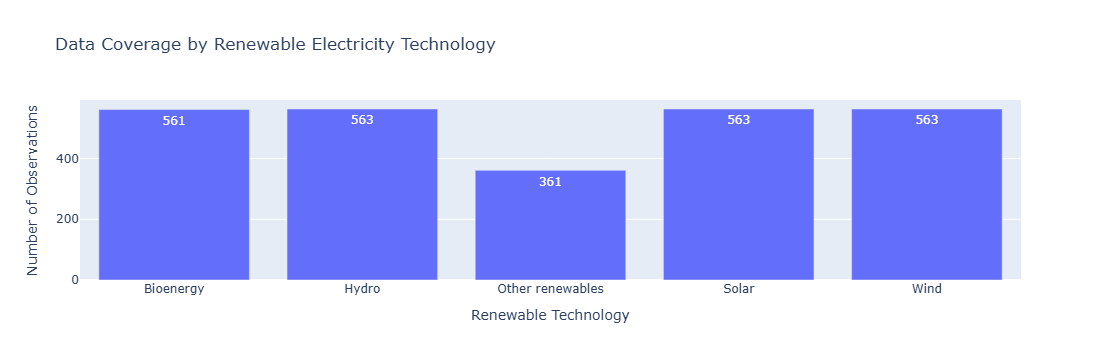

In [82]:
import plotly.express as px

fig = px.bar(
    technology_coverage,
    x="Electricity source",
    y="Observations",
    title="Data Coverage by Renewable Electricity Technology",
    labels={
        "Electricity source": "Renewable Technology",
        "Observations": "Number of Observations"
    },
    text="Observations"
)

fig.update_layout(
    xaxis_title="Renewable Technology",
    yaxis_title="Number of Observations"
)

fig.show()

In [83]:
def descriptive_stats(series):

    # Remove missing values
    series = series.dropna()

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)

    return pd.Series({
        "Count": series.count(),
        "Mean": series.mean(),
        "Median": series.median(),
        "Std": series.std(),
        "Min": series.min(),
        "Q1": q1,
        "Q3": q3,
        "Max": series.max(),
        "IQR": q3 - q1,
        "Skewness": series.skew()
    })

In [84]:
investment_stats = descriptive_stats(
    EDA_investment[
        "Amount (2022 Constant USD million)"
    ]
)

print("Renewable Energy Investment")
display(investment_stats.round(2))

Renewable Energy Investment


Count        528.00
Mean         183.06
Median        40.96
Std          342.97
Min            0.01
Q1             3.43
Q3           216.24
Max         2977.00
IQR          212.81
Skewness       3.56
dtype: float64

In [85]:
renewable_share_stats = descriptive_stats(
    EDA_generation_23_AY[
        "Share of generation (%)"
    ]
)

print("Renewable Share of Electricity Generation")
display(renewable_share_stats.round(2))

Renewable Share of Electricity Generation


Count       528.00
Mean         45.73
Median       35.65
Std          31.38
Min           3.01
Q1           18.59
Q3           73.07
Max         100.00
IQR          54.48
Skewness      0.57
dtype: float64

In [86]:
carbon_stats = descriptive_stats(
    EDA_carbon_trend_23[
        "Emissions intensity (gCO2e/kWh)"
    ]
)

print("Electricity Carbon Intensity")
display(carbon_stats.round(2))

Electricity Carbon Intensity


Count       528.00
Mean        398.72
Median      442.66
Std         230.99
Min          23.29
Q1          198.35
Q3          584.15
Max         790.92
IQR         385.80
Skewness     -0.28
dtype: float64

In [87]:
summary_table = pd.DataFrame({

    "Renewable Investment\n(2022 USD million)":
        descriptive_stats(
            EDA_investment[
                "Amount (2022 Constant USD million)"
            ]
        ),

    "Renewable Generation\n(TWh)":
        descriptive_stats(
            EDA_generation_23_AY[
                "Generation (TWh)"
            ]
        ),

    "Renewable Share\n(%)":
        descriptive_stats(
            EDA_generation_23_AY[
                "Share of generation (%)"
            ]
        ),

    "Carbon Intensity\n(gCO2e/kWh)":
        descriptive_stats(
            EDA_carbon_trend_23[
                "Emissions intensity (gCO2e/kWh)"
            ]
        )
})

summary_table = summary_table.round(2)

summary_table

,Renewable Investment\n(2022 USD million),Renewable Generation\n(TWh),Renewable Share\n(%),Carbon Intensity\n(gCO2e/kWh)
Count,528.00,528.00,528.00,528.00
Mean,183.06,93.31,45.73,398.72
Median,40.96,13.14,35.65,442.66
Std,342.97,305.09,31.38,230.99
Min,0.01,0.28,3.01,23.29
Q1,3.43,2.65,18.59,198.35
Q3,216.24,33.11,73.07,584.15
Max,2977.00,2894.22,100.00,790.92
IQR,212.81,30.46,54.48,385.80
Skewness,3.56,5.93,0.57,-0.28


In [88]:
technology_stats = (
    EDA_generation_23_AYE
    .groupby("Electricity source")["Generation (TWh)"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median",
        Std="std",
        Min="min",
        Max="max"
    )
    .round(2)
)

technology_stats

technology_extra_stats = (
    EDA_generation_23_AYE
    .groupby("Electricity source")["Generation (TWh)"]
    .apply(
        lambda x: pd.Series({
            "Q1": x.quantile(0.25),
            "Q3": x.quantile(0.75),
            "IQR": x.quantile(0.75) - x.quantile(0.25),
            "Skewness": x.skew()
        })
    )
    .unstack()
    .round(2)
)
technology_summary = technology_stats.join(
    technology_extra_stats
)

technology_summary

,Count,Mean,Median,Std,Min,Max,Q1,Q3,IQR,Skewness
Electricity source,,,,,,,,,,
Bioenergy,526,5.59,0.12,18.97,0.00,198.20,0.02,1.27,1.25,6.44
Hydro,528,68.57,9.12,196.77,0.05,1321.71,2.27,26.85,24.58,4.47
Other renewables,340,1.48,0.00,3.70,0.00,16.94,0.00,0.00,0.00,2.39
Solar,528,5.93,0.01,39.53,0.00,584.15,0.00,0.13,0.13,10.40
Wind,528,12.29,0.02,69.65,0.00,885.87,0.00,0.85,0.85,9.05


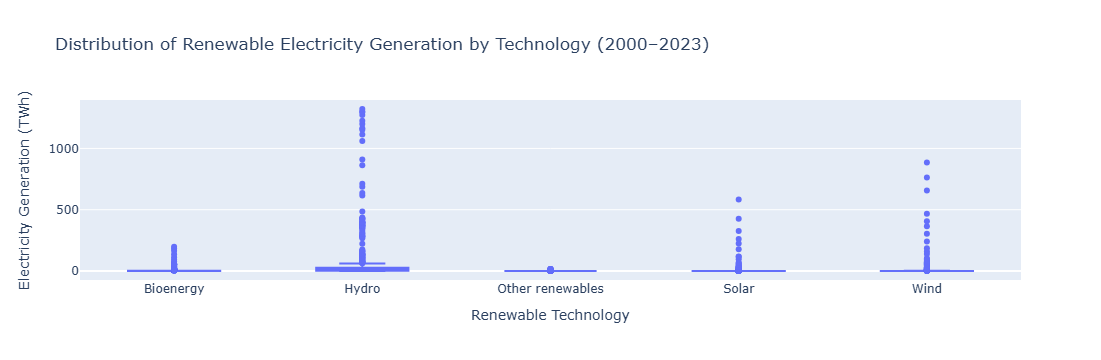

In [89]:
import plotly.express as px

fig = px.box(
    EDA_generation_23_AYE,
    x="Electricity source",
    y="Generation (TWh)",
    points="outliers",
    hover_data=[
        "Area",
        "Year"
    ],
    title="Distribution of Renewable Electricity Generation by Technology (2000–2023)",
    labels={
        "Electricity source": "Renewable Technology",
        "Generation (TWh)": "Electricity Generation (TWh)"
    }
)

fig.update_layout(
    xaxis_title="Renewable Technology",
    yaxis_title="Electricity Generation (TWh)"
)

fig.show()

## Log Tranformed

##### The log-transformed box plot shows substantial differences in renewable generation across technologies. Hydro shows the highest typical generation, while Solar and Wind contain many low-generation country-year observations alongside several high-generation outliers. Bioenergy generation is generally lower, while Other renewables is heavily concentrated around zero. The use of a log transformation improves visibility of these highly skewed distributions without excluding zero-generation observations.

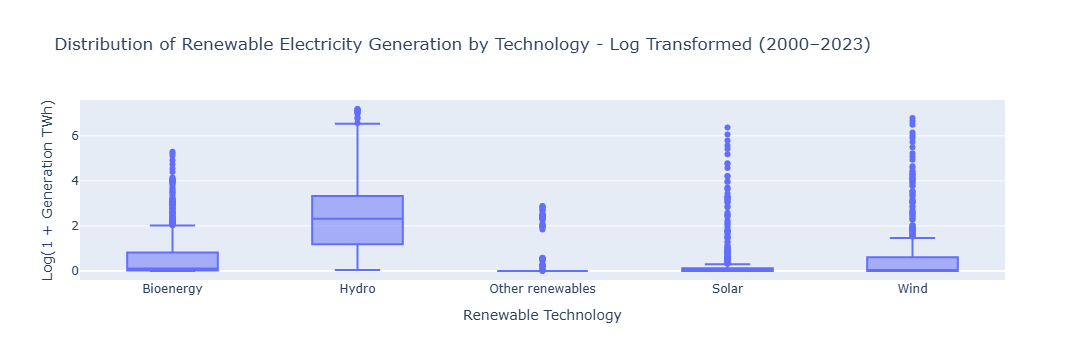

In [90]:
EDA_generation_23_AYE["Log_Generation"] = np.log1p(
    EDA_generation_23_AYE["Generation (TWh)"]
)

fig = px.box(
    EDA_generation_23_AYE,
    x="Electricity source",
    y="Log_Generation",
    points="outliers",
    hover_data=[
        "Area",
        "Year",
        "Generation (TWh)"
    ],
    title="Distribution of Renewable Electricity Generation by Technology - Log Transformed (2000–2023)",
    labels={
        "Electricity source": "Renewable Technology",
        "Log_Generation": "Log(1 + Generation TWh)"
    }
)

fig.show()

### RENEWABLE INVESTMENT DISTRIBUTION AND OUTLIER ANALYSIS

In [91]:
investment_col = "Amount (2022 Constant USD million)"

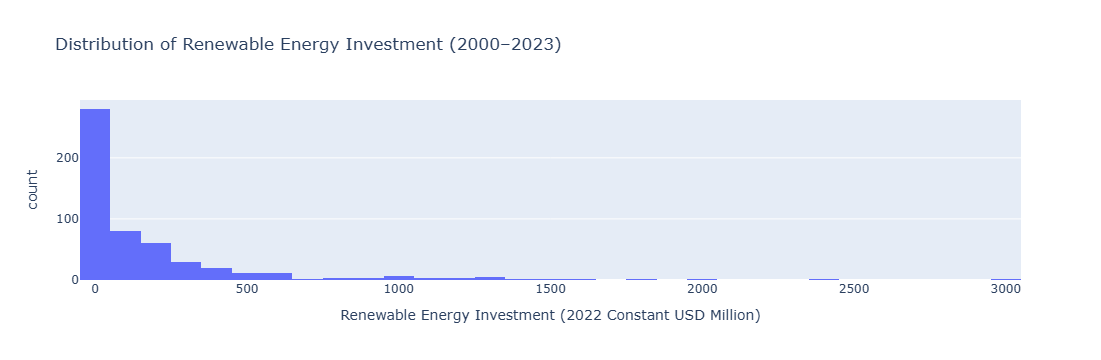

In [92]:
fig = px.histogram(
    EDA_investment,
    x=investment_col,
    nbins=40,
    title="Distribution of Renewable Energy Investment (2000–2023)",
    labels={
        investment_col:
        "Renewable Energy Investment (2022 Constant USD Million)"
    }
)

fig.show()

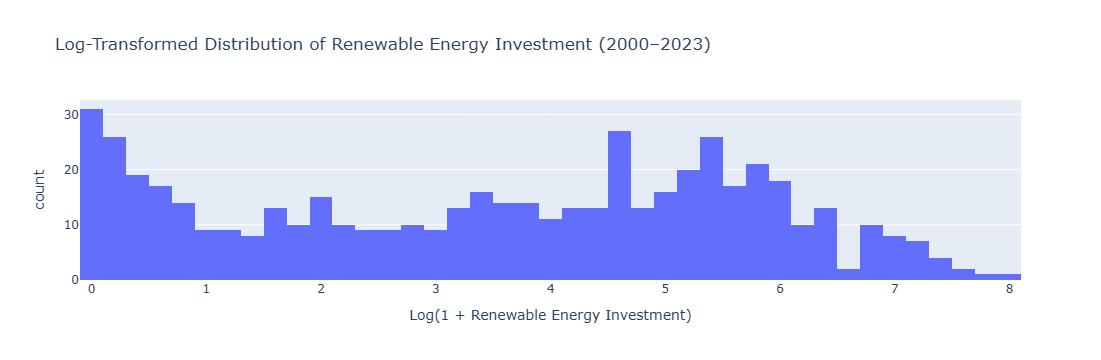

In [93]:
EDA_investment["Log_RE_Investment"] = np.log1p(
    EDA_investment[investment_col]
)

fig = px.histogram(
    EDA_investment,
    x="Log_RE_Investment",
    nbins=40,
    title="Log-Transformed Distribution of Renewable Energy Investment (2000–2023)",
    labels={
        "Log_RE_Investment":
        "Log(1 + Renewable Energy Investment)"
    }
)

fig.show()

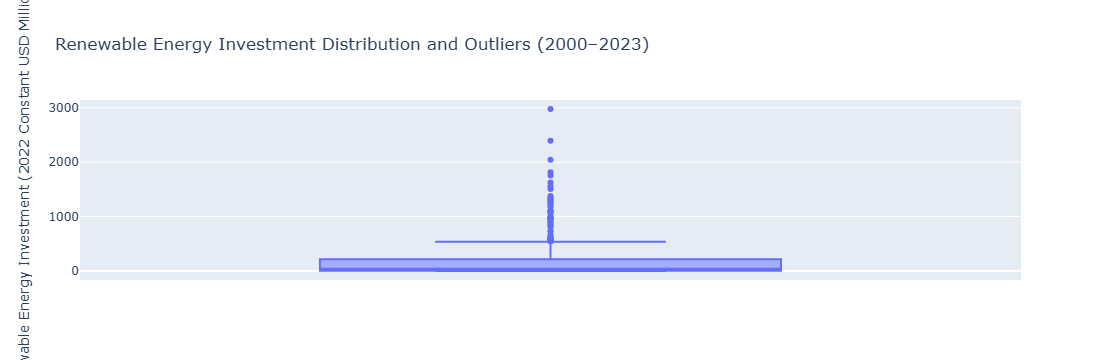

In [94]:
EDA_investment["Log_RE_Investment"] = np.log1p(
    EDA_investment[investment_col]
)

fig = px.box(
    EDA_investment,
    y=investment_col,
    points="outliers",
    hover_data=[
        "Country/Area",
        "Year"
    ],
    title="Renewable Energy Investment Distribution and Outliers (2000–2023)",
    labels={
        investment_col:
        "Renewable Energy Investment (2022 Constant USD Million)"
    }
)

fig.show()



In [95]:
EDA_investment

,Country/Area,Year,Amount (2022 Constant USD million),Log_RE_Investment
237,Bolivia,2000,0.090563,0.086694
238,Bolivia,2001,0.786918,0.580492
239,Bolivia,2002,0.076158,0.073397
240,Bolivia,2003,16.998653,2.890297
241,Bolivia,2004,0.034561,0.033977
...,...,...,...,...
2372,Vietnam,2019,241.986082,5.493004
2373,Vietnam,2020,183.024416,5.215068
2374,Vietnam,2021,421.663652,6.046577
2375,Vietnam,2022,220.284417,5.399449


In [96]:
Q1 = EDA_investment[investment_col].quantile(0.25)
Q3 = EDA_investment[investment_col].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

investment_outliers = EDA_investment[
    (EDA_investment[investment_col] < lower_bound) |
    (EDA_investment[investment_col] > upper_bound)
].copy()

investment_outliers = investment_outliers.sort_values(
    investment_col,
    ascending=False
)

print(
    "Number of investment outliers:",
    len(investment_outliers)
)

investment_outliers.head(20)

Q1: 3.43
Q3: 216.24
IQR: 212.81
Lower Bound: -315.79
Upper Bound: 535.46
Number of investment outliers: 49


,Country/Area,Year,Amount (2022 Constant USD million),Log_RE_Investment
1002,India,2023,2977.004930,7.999009
995,India,2016,2394.905185,7.781516
990,India,2011,2042.374685,7.622358
997,India,2018,1815.018991,7.504402
714,Egypt,2017,1754.465049,7.470489
2271,Uganda,2015,1626.035864,7.394515
1679,Pakistan,2015,1556.412344,7.350781
1473,Morocco,2014,1506.120437,7.317956
1000,India,2021,1376.097357,7.227733
999,India,2020,1342.600668,7.203108


In [97]:
investment_col = "Amount (2022 Constant USD million)"

Q1 = EDA_investment[investment_col].quantile(0.25)
Q3 = EDA_investment[investment_col].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

investment_outliers = EDA_investment[
    (EDA_investment[investment_col] < lower_bound) |
    (EDA_investment[investment_col] > upper_bound)
].copy()

investment_outliers = investment_outliers.sort_values(
    investment_col,
    ascending=False
)

print("Upper outlier threshold:", round(upper_bound, 2))
print("Number of outliers:", len(investment_outliers))

investment_outliers[
    [
        "Country/Area",
        "Year",
        investment_col
    ]
].head(20)

Upper outlier threshold: 535.46
Number of outliers: 49


,Country/Area,Year,Amount (2022 Constant USD million)
1002,India,2023,2977.004930
995,India,2016,2394.905185
990,India,2011,2042.374685
997,India,2018,1815.018991
714,Egypt,2017,1754.465049
2271,Uganda,2015,1626.035864
1679,Pakistan,2015,1556.412344
1473,Morocco,2014,1506.120437
1000,India,2021,1376.097357
999,India,2020,1342.600668


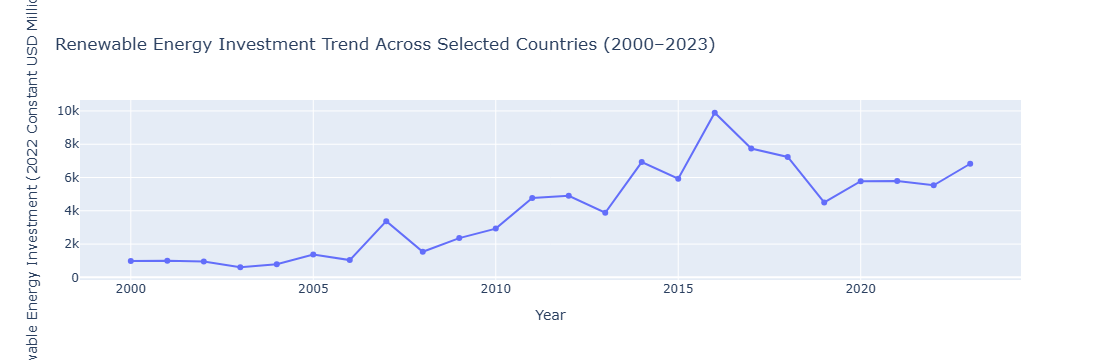

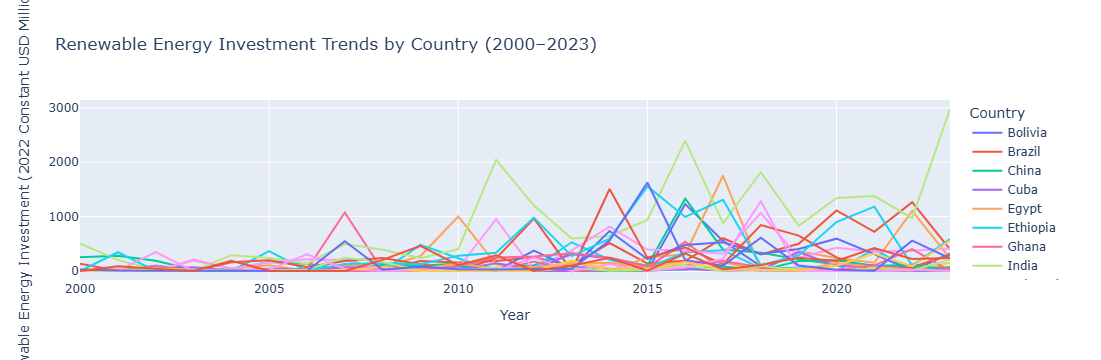

In [98]:
investment_yearly = (
    EDA_investment
    .groupby(
        "Year",
        as_index=False
    )[investment_col]
    .sum()
)

fig = px.line(
    investment_yearly,
    x="Year",
    y=investment_col,
    markers=True,
    title="Renewable Energy Investment Trend Across Selected Countries (2000–2023)",
    labels={
        "Year": "Year",
        investment_col:
        "Renewable Energy Investment (2022 Constant USD Million)"
    }
)

fig.show()

fig = px.line(
    EDA_investment,
    x="Year",
    y=investment_col,
    color="Country/Area",
    title="Renewable Energy Investment Trends by Country (2000–2023)",
    labels={
        "Year": "Year",
        investment_col:
        "Renewable Energy Investment (2022 Constant USD Million)",
        "Country/Area": "Country"
    }
)

fig.show()

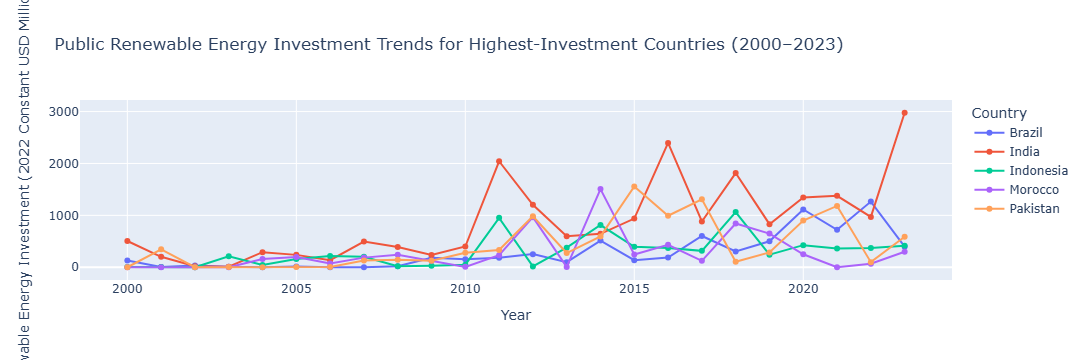

In [99]:
country_total_investment = (
    EDA_investment
    .groupby(
        "Country/Area",
        as_index=False
    )[investment_col]
    .sum()
    .sort_values(
        investment_col,
        ascending=False
    )
)
top_7_countries = (
    country_total_investment
    .head()["Country/Area"]
    .tolist()
)

top_7_investment = EDA_investment[
    EDA_investment["Country/Area"].isin(
        top_7_countries
    )
].copy()

fig = px.line(
    top_7_investment,
    x="Year",
    y=investment_col,
    color="Country/Area",
    markers=True,
    title="Public Renewable Energy Investment Trends for Highest-Investment Countries (2000–2023)",
    labels={
        "Year": "Year",
        investment_col:
        "Renewable Energy Investment (2022 Constant USD Million)",
        "Country/Area": "Country"
    }
)

fig.show()


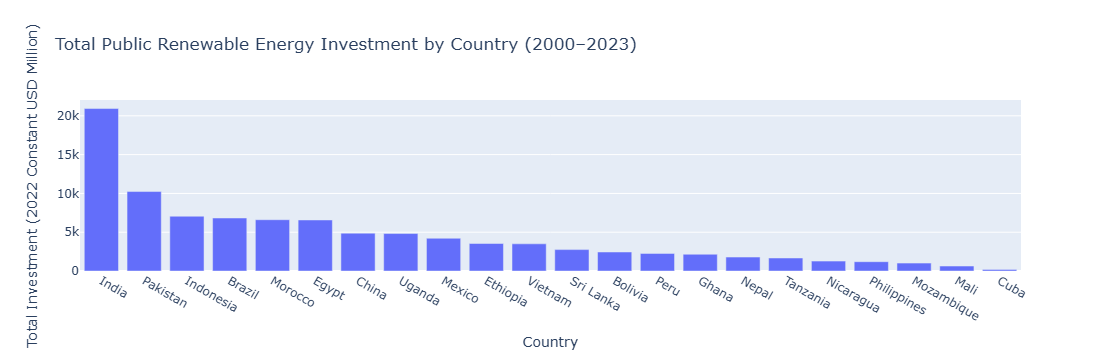

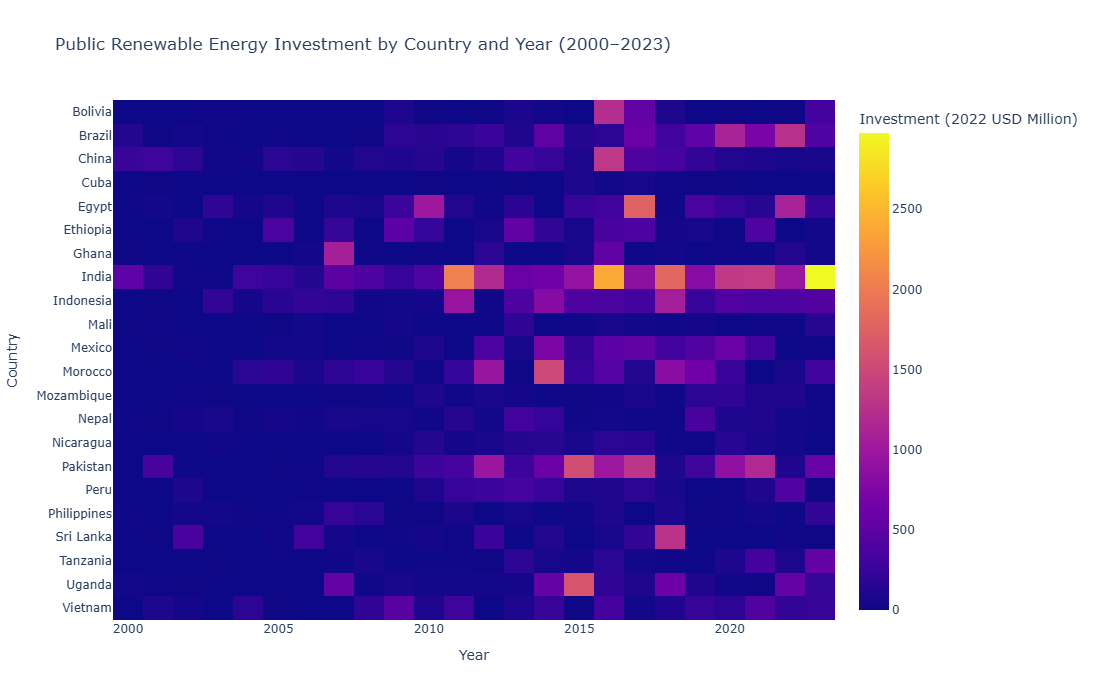

In [100]:
fig = px.bar(
    country_total_investment,
    x="Country/Area",
    y=investment_col,
    title="Total Public Renewable Energy Investment by Country (2000–2023)",
    labels={
        "Country/Area": "Country",
        investment_col:
        "Total Investment (2022 Constant USD Million)"
    }
)

fig.update_xaxes(
    categoryorder="total descending"
)

fig.show()

investment_heatmap = EDA_investment.pivot(
    index="Country/Area",
    columns="Year",
    values=investment_col
)

fig = px.imshow(
    investment_heatmap,
    aspect="auto",
    title="Public Renewable Energy Investment by Country and Year (2000–2023)",
    labels={
        "x": "Year",
        "y": "Country",
        "color": "Investment (2022 USD Million)"
    }
)

fig.update_layout(
    height=700
)

fig.show()

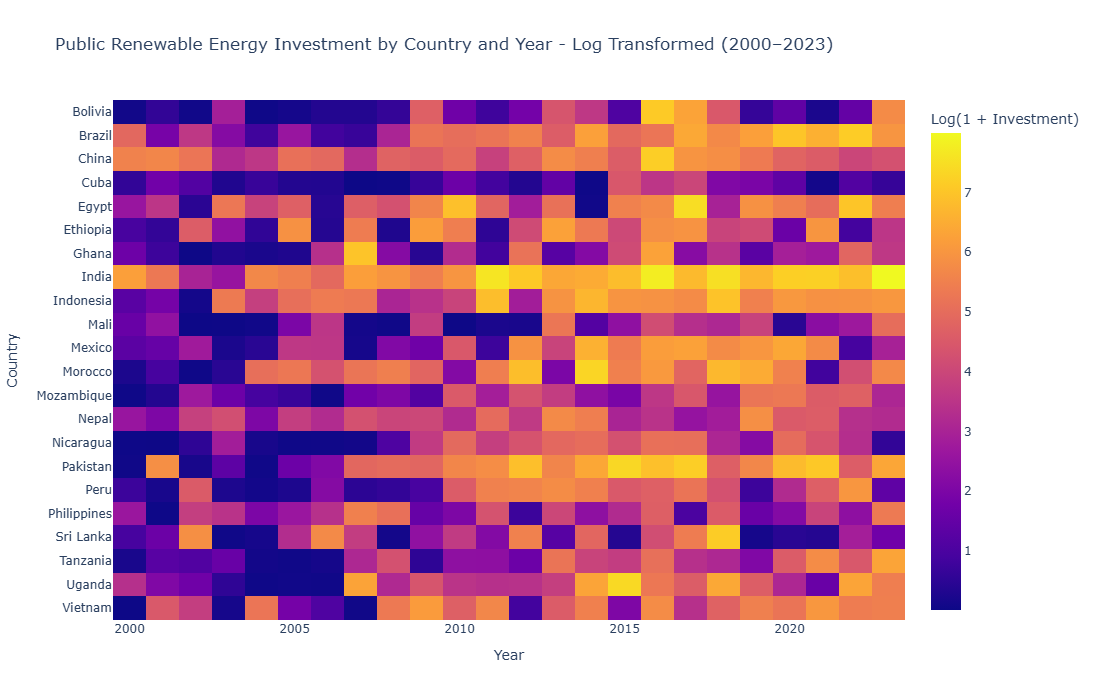

In [101]:
investment_heatmap_log = EDA_investment.pivot(
    index="Country/Area",
    columns="Year",
    values="Log_RE_Investment"
)

fig = px.imshow(
    investment_heatmap_log,
    aspect="auto",
    title="Public Renewable Energy Investment by Country and Year - Log Transformed (2000–2023)",
    labels={
        "x": "Year",
        "y": "Country",
        "color": "Log(1 + Investment)"
    }
)

fig.update_layout(
    height=700
)

fig.show()

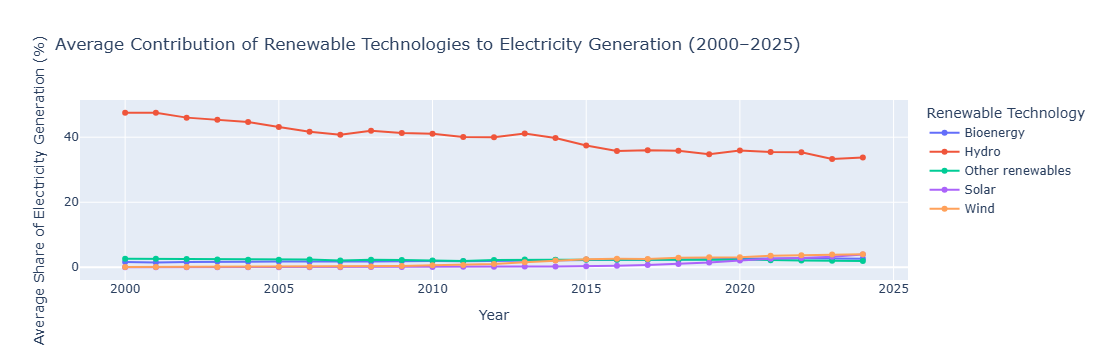

In [102]:
technology_share_yearly = (
    EDA_generation_trend_AYE_24
    .groupby(
        ["Year", "Electricity source"],
        as_index=False
    )["Share of generation (%)"].mean()
)

fig = px.line(
    technology_share_yearly,
    x="Year",
    y="Share of generation (%)",
    color="Electricity source",
    markers=True,
    title="Average Contribution of Renewable Technologies to Electricity Generation (2000–2025)",
    labels={
        "Year": "Year",
        "Share of generation (%)":
            "Average Share of Electricity Generation (%)",
        "Electricity source":
            "Renewable Technology"
    }
)

fig.show()

In [103]:
renewable_share_yearly = (
    EDA_generation_trend_AY
    .groupby(
        "Year",
        as_index=False
    )["Share of generation (%)"]
    .mean()
)

carbon_intensity_yearly = (
    EDA_carbon_trend_25
    .groupby(
        "Year",
        as_index=False
    )["Emissions intensity (gCO2e/kWh)"]
    .mean()
)

renewable_carbon_yearly = (
    renewable_share_yearly
    .merge(
        carbon_intensity_yearly,
        on="Year",
        how="inner"
    )
)

renewable_carbon_yearly

,Year,Share of generation (%),Emissions intensity (gCO2e/kWh)
0,2000,50.808864,372.860318
1,2001,50.754182,372.167182
2,2002,49.238273,379.780909
3,2003,48.679273,382.767227
4,2004,47.999000,384.584955
5,2005,46.448636,392.122318
6,2006,45.053591,399.913409
7,2007,44.087182,406.135045
8,2008,45.491909,394.943545
9,2009,45.080727,396.396409


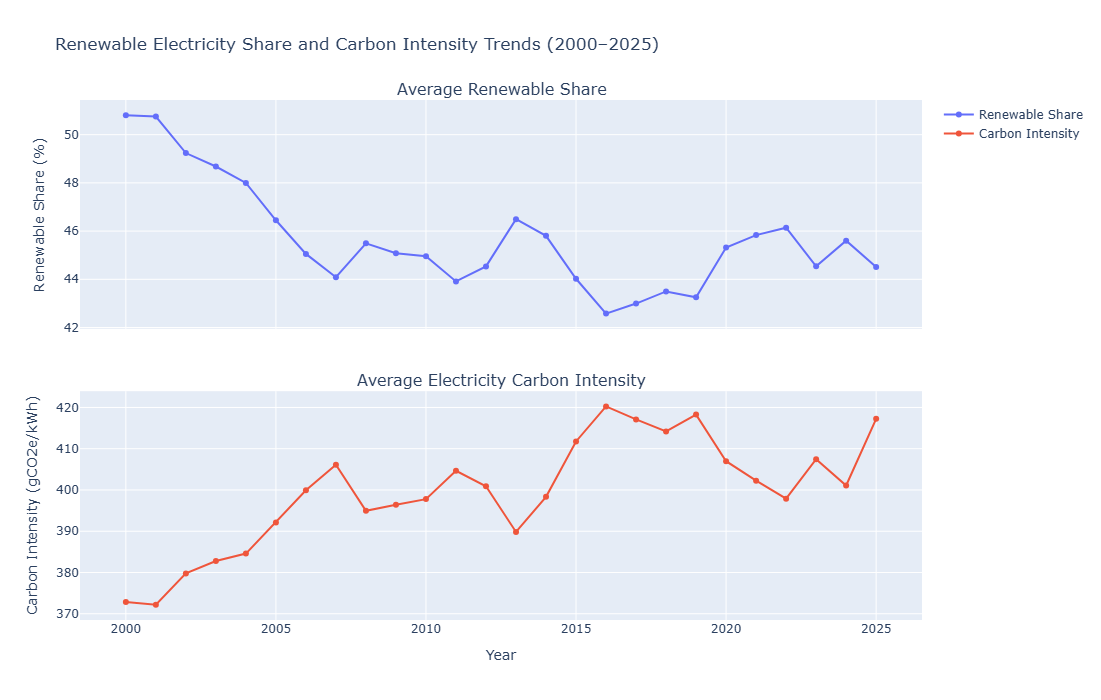

In [104]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

fig = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.12,
    subplot_titles=(
        "Average Renewable Share",
        "Average Electricity Carbon Intensity"
    )
)

fig.add_trace(
    go.Scatter(
        x=renewable_carbon_yearly["Year"],
        y=renewable_carbon_yearly[
            "Share of generation (%)"
        ],
        mode="lines+markers",
        name="Renewable Share"
    ),
    row=1,
    col=1
)

fig.add_trace(
    go.Scatter(
        x=renewable_carbon_yearly["Year"],
        y=renewable_carbon_yearly[
            "Emissions intensity (gCO2e/kWh)"
        ],
        mode="lines+markers",
        name="Carbon Intensity"
    ),
    row=2,
    col=1
)

fig.update_yaxes(
    title_text="Renewable Share (%)",
    row=1,
    col=1
)

fig.update_yaxes(
    title_text="Carbon Intensity (gCO2e/kWh)",
    row=2,
    col=1
)

fig.update_xaxes(
    title_text="Year",
    row=2,
    col=1
)

fig.update_layout(
    height=700,
    title="Renewable Electricity Share and Carbon Intensity Trends (2000–2025)"
)

fig.show()

In [105]:
country_year_analysis = (
    EDA_generation_trend_AY[
        [
            "Area",
            "Year",
            "Share of generation (%)"
        ]
    ]
    .merge(
        EDA_carbon_trend_25[
            [
                "Area",
                "Year",
                "Emissions intensity (gCO2e/kWh)"
            ]
        ],
        on=[
            "Area",
            "Year"
        ],
        how="inner"
    )
)

country_2000 = (
    country_year_analysis[
        country_year_analysis["Year"] == 2000
    ]
    .copy()
)

country_2000 = country_2000.rename(
    columns={
        "Share of generation (%)":
            "Renewable_Share_2000",

        "Emissions intensity (gCO2e/kWh)":
            "Carbon_Intensity_2000"
    }
)

country_2025 = (
    country_year_analysis[
        country_year_analysis["Year"] == 2025
    ]
    .copy()
)

country_2025 = country_2025.rename(
    columns={
        "Share of generation (%)":
            "Renewable_Share_2025",

        "Emissions intensity (gCO2e/kWh)":
            "Carbon_Intensity_2025"
    }
)

country_change = country_2000[
    [
        "Area",
        "Renewable_Share_2000",
        "Carbon_Intensity_2000"
    ]
].merge(
    country_2025[
        [
            "Area",
            "Renewable_Share_2025",
            "Carbon_Intensity_2025"
        ]
    ],
    on="Area",
    how="inner"
)
country_change["Renewable_Share_Change"] = (
    country_change["Renewable_Share_2025"]
    -
    country_change["Renewable_Share_2000"]
)

country_change["Carbon_Intensity_Change"] = (
    country_change["Carbon_Intensity_2025"]
    -
    country_change["Carbon_Intensity_2000"]
)

country_change[
    [
        "Area",
        "Renewable_Share_Change",
        "Carbon_Intensity_Change"
    ]
].sort_values(
    "Renewable_Share_Change",
    ascending=False
)

,Area,Renewable_Share_Change,Carbon_Intensity_Change
8,Pakistan,21.135,-191.900
2,China,20.342,-257.318
7,Morocco,17.665,-156.851
5,India,10.018,-69.484
11,Sri Lanka,8.932,9.985
6,Mexico,3.713,-51.305
4,Ethiopia,1.183,-12.691
1,Brazil,-2.860,20.400
3,Egypt,-6.434,37.565
12,Vietnam,-9.504,142.055


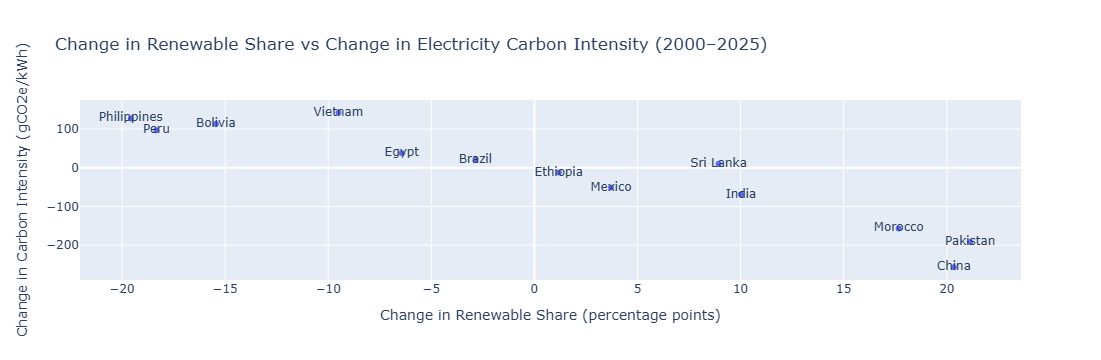

In [106]:
fig = px.scatter(
    country_change,
    x="Renewable_Share_Change",
    y="Carbon_Intensity_Change",
    text="Area",
    hover_data=[
        "Renewable_Share_2000",
        "Renewable_Share_2025",
        "Carbon_Intensity_2000",
        "Carbon_Intensity_2025"
    ],
    title="Change in Renewable Share vs Change in Electricity Carbon Intensity (2000–2025)",
    labels={
        "Renewable_Share_Change":
            "Change in Renewable Share (percentage points)",

        "Carbon_Intensity_Change":
            "Change in Carbon Intensity (gCO2e/kWh)"
    }
)



fig.show()

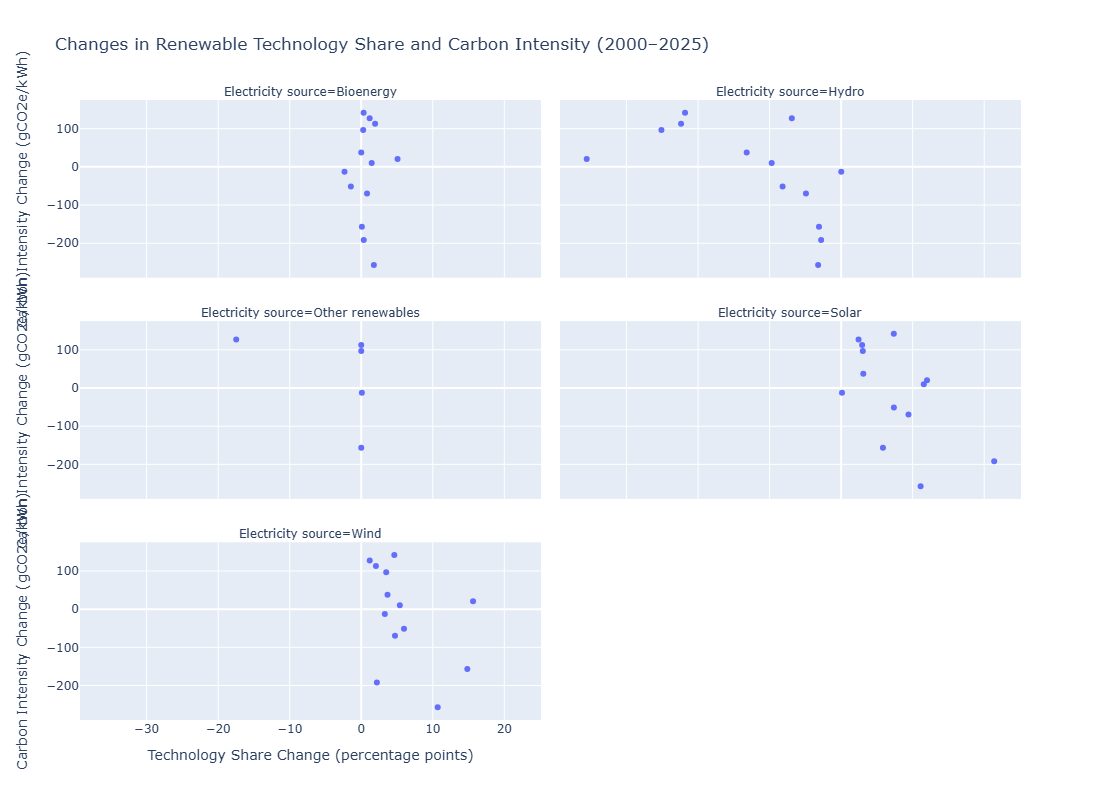

In [107]:

technology_2000 = technology_2000.rename(
    columns={
        "Share of generation (%)":
            "Technology_Share_2000"
    }
)

technology_2025 = EDA_generation_trend_AYE[
    EDA_generation_trend_AYE["Year"] == 2025
][
    [
        "Area",
        "Electricity source",
        "Share of generation (%)"
    ]
].copy()

technology_2025 = technology_2025.rename(
    columns={
        "Share of generation (%)":
            "Technology_Share_2025"
    }
)


technology_change = technology_2000.merge(
    technology_2025,
    on=[
        "Area",
        "Electricity source"
    ],
    how="inner"
)
technology_change["Technology_Share_Change"] = (
    technology_change["Technology_Share_2025"]
    -
    technology_change["Technology_Share_2000"]
)
technology_change = technology_change.merge(
    country_change[
        [
            "Area",
            "Carbon_Intensity_Change"
        ]
    ],
    on="Area",
    how="inner"
)
technology_change.groupby(
    "Electricity source"
)["Area"].nunique()

fig = px.scatter(
    technology_change,
    x="Technology_Share_Change",
    y="Carbon_Intensity_Change",
    facet_col="Electricity source",
    facet_col_wrap=2,
    hover_name="Area",
    height=800,
    title="Changes in Renewable Technology Share and Carbon Intensity (2000–2025)",
    labels={
        "Technology_Share_Change":
            "Technology Share Change (percentage points)",

        "Carbon_Intensity_Change":
            "Carbon Intensity Change (gCO2e/kWh)"
    }
)

fig.show()

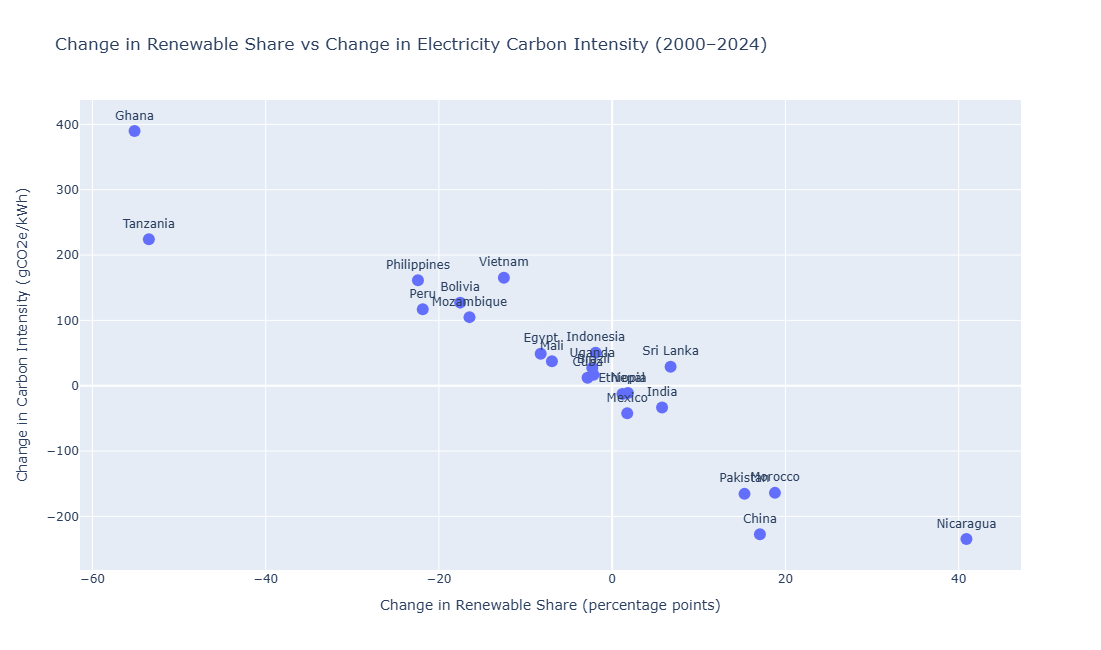

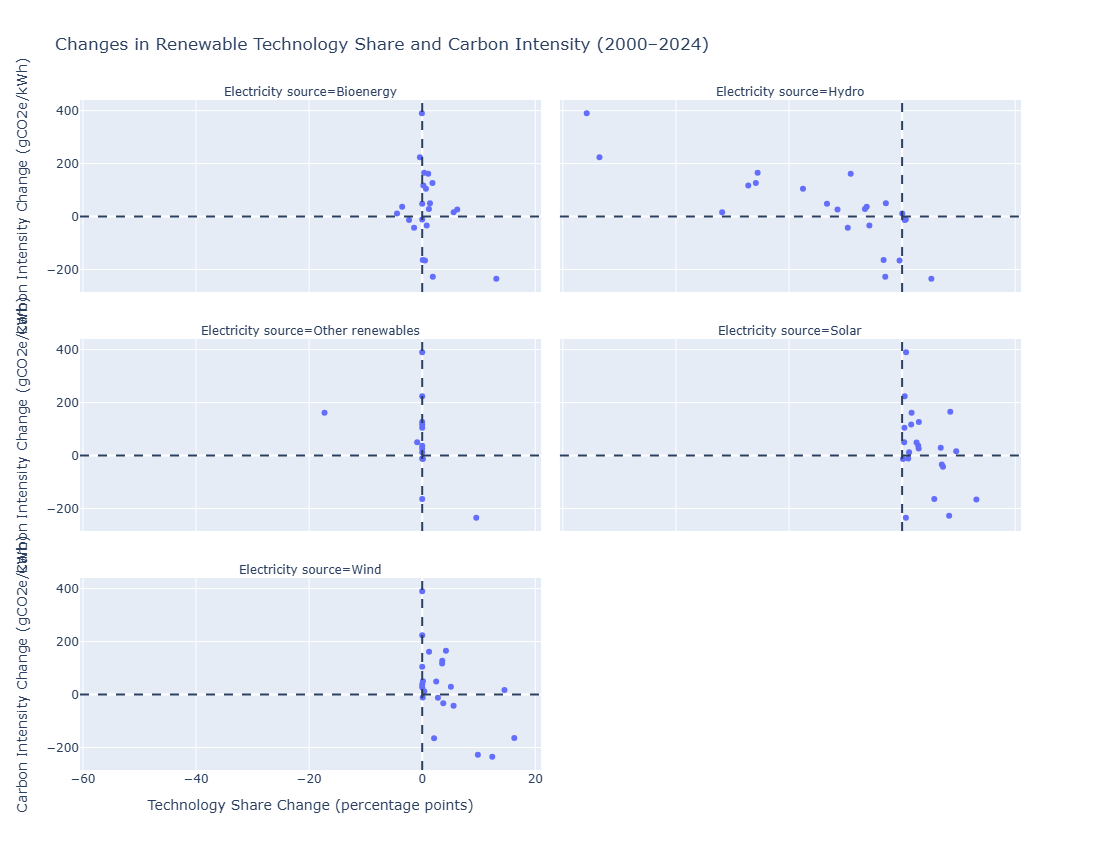

In [108]:

# RO1
# RENEWABLE SHARE / TECHNOLOGY SHARE VS CARBON INTENSITY CHANGE


import plotly.express as px


# CREATE MAIN 2000-2024 DATASETS


# Renewable generation by technology
EDA_generation_trend_AYE_24 = RE_carbon_grouped_AYE[
    (RE_carbon_grouped_AYE["Area"].isin(selected_countries)) &
    (RE_carbon_grouped_AYE["Year"].between(2000, 2024))
].copy()


# Total renewable generation / renewable share
EDA_generation_trend_AY_24 = RE_carbon_grouped_AY[
    (RE_carbon_grouped_AY["Area"].isin(selected_countries)) &
    (RE_carbon_grouped_AY["Year"].between(2000, 2024))
].copy()


# Overall electricity carbon intensity
EDA_carbon_trend_24 = RE_carbon_target[
    (RE_carbon_target["Area"].isin(selected_countries)) &
    (RE_carbon_target["Year"].between(2000, 2024))
].copy()


# MERGE TOTAL RENEWABLE SHARE WITH CARBON INTENSITY


country_year_analysis_24 = (
    EDA_generation_trend_AY_24[
        [
            "Area",
            "Year",
            "Share of generation (%)"
        ]
    ]
    .merge(
        EDA_carbon_trend_24[
            [
                "Area",
                "Year",
                "Emissions intensity (gCO2e/kWh)"
            ]
        ],
        on=["Area", "Year"],
        how="inner"
    )
)


# GET VALUES FOR YEAR 2000


country_2000 = country_year_analysis_24[
    country_year_analysis_24["Year"] == 2000
][
    [
        "Area",
        "Share of generation (%)",
        "Emissions intensity (gCO2e/kWh)"
    ]
].copy()


country_2000 = country_2000.rename(
    columns={
        "Share of generation (%)":
            "Renewable_Share_2000",

        "Emissions intensity (gCO2e/kWh)":
            "Carbon_Intensity_2000"
    }
)


# GET VALUES FOR YEAR 2024

country_2024 = country_year_analysis_24[
    country_year_analysis_24["Year"] == 2024
][
    [
        "Area",
        "Share of generation (%)",
        "Emissions intensity (gCO2e/kWh)"
    ]
].copy()


country_2024 = country_2024.rename(
    columns={
        "Share of generation (%)":
            "Renewable_Share_2024",

        "Emissions intensity (gCO2e/kWh)":
            "Carbon_Intensity_2024"
    }
)


# MERGE 2000 AND 2024


country_change_24 = country_2000.merge(
    country_2024,
    on="Area",
    how="inner"
)


# CALCULATE CHANGE

country_change_24["Renewable_Share_Change"] = (
    country_change_24["Renewable_Share_2024"]
    -
    country_change_24["Renewable_Share_2000"]
)


country_change_24["Carbon_Intensity_Change"] = (
    country_change_24["Carbon_Intensity_2024"]
    -
    country_change_24["Carbon_Intensity_2000"]
)



# CHECK COUNTRY COVERAGE



# SCATTER:
# TOTAL RENEWABLE SHARE CHANGE VS CARBON INTENSITY CHANGE


fig = px.scatter(
    country_change_24,
    x="Renewable_Share_Change",
    y="Carbon_Intensity_Change",
    text="Area",

    hover_data=[
        "Renewable_Share_2000",
        "Renewable_Share_2024",
        "Carbon_Intensity_2000",
        "Carbon_Intensity_2024"
    ],

    title=(
        "Change in Renewable Share vs Change in "
        "Electricity Carbon Intensity (2000–2024)"
    ),

    labels={
        "Renewable_Share_Change":
            "Change in Renewable Share (percentage points)",

        "Carbon_Intensity_Change":
            "Change in Carbon Intensity (gCO2e/kWh)"
    },
    width=1000,
    height=650
)
fig.update_traces(
    marker=dict(size=12),
    textposition="top center"
)
fig.show()



# TECHNOLOGY-SPECIFIC VALUES FOR 2000


technology_2000 = EDA_generation_trend_AYE_24[
    EDA_generation_trend_AYE_24["Year"] == 2000
][
    [
        "Area",
        "Electricity source",
        "Share of generation (%)"
    ]
].copy()


technology_2000 = technology_2000.rename(
    columns={
        "Share of generation (%)":
            "Technology_Share_2000"
    }
)


# TECHNOLOGY-SPECIFIC VALUES FOR 2024


technology_2024 = EDA_generation_trend_AYE_24[
    EDA_generation_trend_AYE_24["Year"] == 2024
][
    [
        "Area",
        "Electricity source",
        "Share of generation (%)"
    ]
].copy()


technology_2024 = technology_2024.rename(
    columns={
        "Share of generation (%)":
            "Technology_Share_2024"
    }
)



# MERGE TECHNOLOGY VALUES: 2000 + 2024


technology_change_24 = technology_2000.merge(
    technology_2024,
    on=[
        "Area",
        "Electricity source"
    ],
    how="inner"
)



# CALCULATE TECHNOLOGY SHARE CHANGE


technology_change_24["Technology_Share_Change"] = (
    technology_change_24["Technology_Share_2024"]
    -
    technology_change_24["Technology_Share_2000"]
)



# ADD CARBON INTENSITY CHANGE


technology_change_24 = technology_change_24.merge(
    country_change_24[
        [
            "Area",
            "Carbon_Intensity_Change"
        ]
    ],
    on="Area",
    how="inner"
)


# TECHNOLOGY SHARE CHANGE VS CARBON INTENSITY CHANGE

fig = px.scatter(
    technology_change_24,

    x="Technology_Share_Change",
    y="Carbon_Intensity_Change",

    facet_col="Electricity source",
    facet_col_wrap=2,

    hover_name="Area",

    hover_data=[
        "Technology_Share_2000",
        "Technology_Share_2024"
    ],
    width=1200,
    height=850,

    title=(
        "Changes in Renewable Technology Share and "
        "Carbon Intensity (2000–2024)"
    ),

    labels={
        "Technology_Share_Change":
            "Technology Share Change (percentage points)",

        "Carbon_Intensity_Change":
            "Carbon Intensity Change (gCO2e/kWh)"
    },
    
)


# Zero reference lines
fig.add_hline(
    y=0,
    line_dash="dash"
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.show()

### Carbon Intensity Data

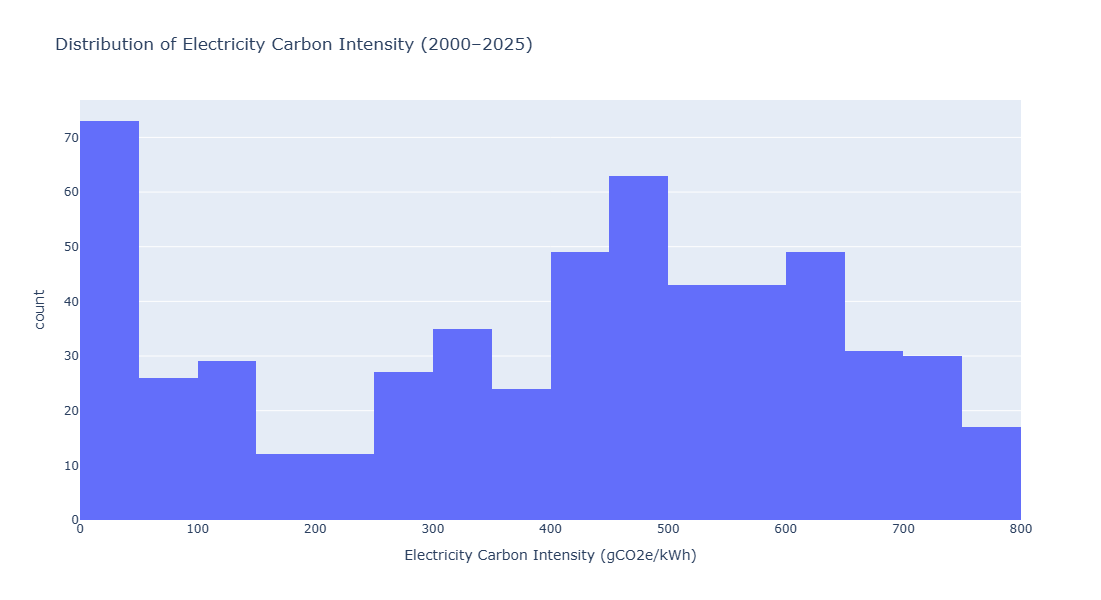

In [109]:
fig = px.histogram(
    EDA_carbon_trend_25,
    x="Emissions intensity (gCO2e/kWh)",
    nbins=30,
    title="Distribution of Electricity Carbon Intensity (2000–2025)",
    labels={
        "Emissions intensity (gCO2e/kWh)":
            "Electricity Carbon Intensity (gCO2e/kWh)"
    }
)

fig.update_layout(
    width=950,
    height=600
)

fig.show()

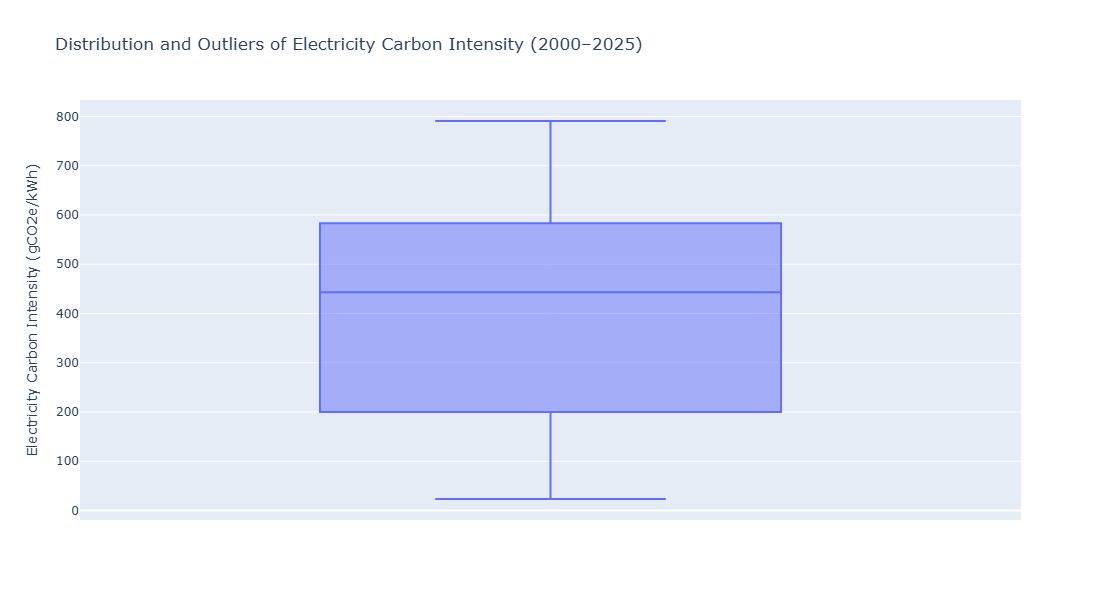

In [110]:
fig = px.box(
    EDA_carbon_trend_25,
    y="Emissions intensity (gCO2e/kWh)",
    points="outliers",
    hover_data=[
        "Area",
        "Year"
    ],
    title="Distribution and Outliers of Electricity Carbon Intensity (2000–2025)",
    labels={
        "Emissions intensity (gCO2e/kWh)":
            "Electricity Carbon Intensity (gCO2e/kWh)"
    }
)

fig.update_layout(
    width=850,
    height=600
)

fig.show()

In [111]:
carbon_col = "Emissions intensity (gCO2e/kWh)"

carbon_summary = EDA_carbon_trend_25[carbon_col].describe()

print(carbon_summary)

print(
    "\nSkewness:",
    EDA_carbon_trend_25[carbon_col].skew()
)

count    563.000000
mean     399.240497
std      229.549374
min       23.292000
25%      200.123500
50%      443.383000
75%      583.215000
max      790.918000
Name: Emissions intensity (gCO2e/kWh), dtype: float64

Skewness: -0.28900622466281845


In [112]:
country_carbon_average = (
    EDA_carbon_trend_23
    .groupby(
        "Area",
        as_index=False
    )[carbon_col]
    .mean()
    .sort_values(
        carbon_col,
        ascending=False
    )
)

country_carbon_average

,Area,Emissions intensity (gCO2e/kWh)
7,India,734.039542
2,China,706.882333
11,Morocco,672.138167
8,Indonesia,668.822667
3,Cuba,642.567458
4,Egypt,572.312833
10,Mexico,530.539667
17,Philippines,517.702625
0,Bolivia,466.494500
15,Pakistan,449.943333


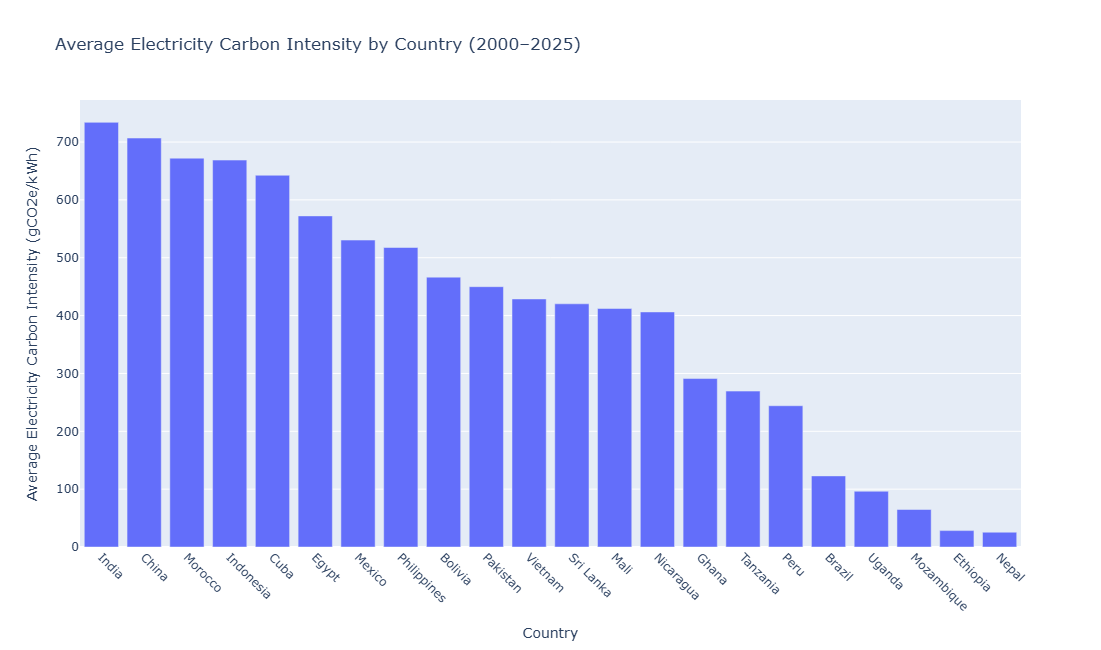

In [113]:
fig = px.bar(
    country_carbon_average,
    x="Area",
    y=carbon_col,
    title="Average Electricity Carbon Intensity by Country (2000–2025)",
    labels={
        "Area": "Country",
        carbon_col:
            "Average Electricity Carbon Intensity (gCO2e/kWh)"
    }
)

fig.update_xaxes(
    categoryorder="total descending",
    tickangle=45
)

fig.update_layout(
    width=1100,
    height=650
)

fig.show()

In [114]:
RO2_energy = pd.read_csv("release_generation_yearly_global.csv")

RO2_energy = RO2_energy.drop_duplicates()
RO2_energy = RO2_energy.dropna(how = "all")

RO2_energy['Area'] = (RO2_energy['Area'].str.replace(r"\s*\(.*?\)","",regex=True).str.strip())

RO2_energy["Area"] = RO2_energy["Area"].replace({
    "Viet Nam": "Vietnam",
    "The Philippines": "Philippines",
    "United Republic of Tanzania": "Tanzania"
})


# Keep actual countries only
RO2_energy = RO2_energy[
    RO2_energy["Area type"] == "Country or economy"
].copy()


# Keep 22 selected countries and common years


RO2_energy = RO2_energy[
    (RO2_energy["Area"].isin(selected_countries)) &
    (RO2_energy["Year"].between(2000, 2023))
].copy()


# Technologies needed for RO2


RO2_sources = [
    "Solar",
    "Wind",
    "Hydro",
    "Bioenergy",
    "Other renewables",
    "Renewables",
    "Coal",
    "Gas",
    "Other fossil",
    "Nuclear"
]

RO2_energy = RO2_energy[
    RO2_energy["Electricity source"].isin(
        RO2_sources
    )
].copy()


# Make generation and share numeric

RO2_energy["Generation (TWh)"] = pd.to_numeric(
    RO2_energy["Generation (TWh)"],
    errors="coerce"
)

RO2_energy["Share of generation (%)"] = pd.to_numeric(
    RO2_energy["Share of generation (%)"],
    errors="coerce"
)

In [115]:
RO2_share = RO2_energy.pivot_table(
    index=["Area", "Year"],
    columns="Electricity source",
    values="Share of generation (%)",
    aggfunc="first"
).reset_index()

RO2_share = RO2_share.rename(
    columns={
        "Solar": "Solar_Share",
        "Wind": "Wind_Share",
        "Hydro": "Hydro_Share",
        "Bioenergy": "Bioenergy_Share",
        "Other renewables": "Other_Renewables_Share",
        "Renewables": "Renewable_Share",
        "Coal": "Coal_Share",
        "Gas": "Gas_Share",
        "Other fossil": "Other_Fossil_Share",
        "Nuclear": "Nuclear_Share"
    }
)

RO2_share.head()

Electricity source,Area,Year,Bioenergy_Share,Coal_Share,Gas_Share,Hydro_Share,Nuclear_Share,Other_Fossil_Share,Other_Renewables_Share,Renewable_Share,Solar_Share,Wind_Share
0,Bolivia,2000,1.289,0.0,47.680,50.258,0.0,0.773,0.0,51.546,0.0,0.0
1,Bolivia,2001,1.263,0.0,44.192,53.283,0.0,1.263,0.0,54.545,0.0,0.0
2,Bolivia,2002,1.202,0.0,45.192,52.404,0.0,1.202,0.0,53.606,0.0,0.0
3,Bolivia,2003,1.155,0.0,51.963,45.497,0.0,1.386,0.0,46.651,0.0,0.0
4,Bolivia,2004,1.325,0.0,50.331,47.020,0.0,1.325,0.0,48.344,0.0,0.0


In [116]:
RO2_generation = RO2_energy[
    RO2_energy["Electricity source"].isin(
        [
            "Solar",
            "Wind",
            "Hydro",
            "Bioenergy",
            "Other renewables"
        ]
    )
].pivot_table(
    index=["Area", "Year"],
    columns="Electricity source",
    values="Generation (TWh)",
    aggfunc="first"
).reset_index()

RO2_generation = RO2_generation.rename(
    columns={
        "Solar": "Solar_TWh",
        "Wind": "Wind_TWh",
        "Hydro": "Hydro_TWh",
        "Bioenergy": "Bioenergy_TWh",
        "Other renewables": "Other_Renewables_TWh"
    }
)

RO2_generation.head()

Electricity source,Area,Year,Bioenergy_TWh,Hydro_TWh,Other_Renewables_TWh,Solar_TWh,Wind_TWh
0,Bolivia,2000,0.05,1.95,0.0,0.0,0.0
1,Bolivia,2001,0.05,2.11,0.0,0.0,0.0
2,Bolivia,2002,0.05,2.18,0.0,0.0,0.0
3,Bolivia,2003,0.05,1.97,0.0,0.0,0.0
4,Bolivia,2004,0.06,2.13,0.0,0.0,0.0


In [117]:
RO2_investment = EDA_investment[
    [
        "Country/Area",
        "Year",
        "Amount (2022 Constant USD million)"
    ]
].copy()
RO2_investment = RO2_investment.rename(
    columns={
        "Country/Area": "Area",
        "Amount (2022 Constant USD million)":
            "RE_Investment"
    }
)
RO2_target = EDA_carbon_trend_23[
    [
        "Area",
        "Year",
        "Emissions intensity (gCO2e/kWh)"
    ]
].copy()
RO2_target = RO2_target.rename(
    columns={
        "Emissions intensity (gCO2e/kWh)":
            "Carbon_Intensity"
    }
)

In [118]:
RO2_data = (
    RO2_investment
    .merge(
        RO2_share,
        on=["Area", "Year"],
        how="inner"
    )
    .merge(
        RO2_generation,
        on=["Area", "Year"],
        how="inner"
    )
    .merge(
        RO2_target,
        on=["Area", "Year"],
        how="inner"
    )
)

In [119]:
RO2_data = RO2_data.sort_values(
    ["Area", "Year"]
).reset_index(drop=True)
RO2_data.head(10)

,Area,Year,RE_Investment,Bioenergy_Share,Coal_Share,Gas_Share,Hydro_Share,Nuclear_Share,Other_Fossil_Share,Other_Renewables_Share,Renewable_Share,Solar_Share,Wind_Share,Bioenergy_TWh,Hydro_TWh,Other_Renewables_TWh,Solar_TWh,Wind_TWh,Carbon_Intensity
0,Bolivia,2000,0.090563,1.289,0.0,47.680,50.258,0.0,0.773,0.0,51.546,0.0,0.0,0.05,1.95,0.0,0.0,0.0,368.557
1,Bolivia,2001,0.786918,1.263,0.0,44.192,53.283,0.0,1.263,0.0,54.545,0.0,0.0,0.05,2.11,0.0,0.0,0.0,346.970
2,Bolivia,2002,0.076158,1.202,0.0,45.192,52.404,0.0,1.202,0.0,53.606,0.0,0.0,0.05,2.18,0.0,0.0,0.0,353.365
3,Bolivia,2003,16.998653,1.155,0.0,51.963,45.497,0.0,1.386,0.0,46.651,0.0,0.0,0.05,1.97,0.0,0.0,0.0,402.309
4,Bolivia,2004,0.034561,1.325,0.0,50.331,47.020,0.0,1.325,0.0,48.344,0.0,0.0,0.06,2.13,0.0,0.0,0.0,390.728
5,Bolivia,2005,0.149606,1.227,0.0,57.873,39.673,0.0,1.227,0.0,40.900,0.0,0.0,0.06,1.94,0.0,0.0,0.0,443.354
6,Bolivia,2006,0.428464,0.800,0.0,55.600,42.800,0.0,0.800,0.0,43.600,0.0,0.0,0.04,2.14,0.0,0.0,0.0,423.800
7,Bolivia,2007,0.414226,0.919,0.0,55.882,42.279,0.0,0.919,0.0,43.199,0.0,0.0,0.05,2.30,0.0,0.0,0.0,426.654
8,Bolivia,2008,0.850815,1.014,0.0,59.628,38.682,0.0,0.676,0.0,39.696,0.0,0.0,0.06,2.29,0.0,0.0,0.0,451.858
9,Bolivia,2009,107.113849,1.288,0.0,61.353,36.554,0.0,0.805,0.0,37.842,0.0,0.0,0.08,2.27,0.0,0.0,0.0,465.378


In [120]:
print("Rows:", len(RO2_data))

print(
    "Countries:",
    RO2_data["Area"].nunique()
)

print(
    "Years:",
    RO2_data["Year"].min(),
    "-",
    RO2_data["Year"].max()
)

print(
    "Duplicate Area-Year rows:",
    RO2_data[
        ["Area", "Year"]
    ].duplicated().sum()
)

Rows: 528
Countries: 22
Years: 2000 - 2023
Duplicate Area-Year rows: 0


In [121]:
missing_values = (
    RO2_data
    .isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_values

Other_Renewables_Share    188
Other_Renewables_TWh      188
Nuclear_Share              82
Gas_Share                  24
Coal_Share                 11
Bioenergy_Share             2
Bioenergy_TWh               2
Wind_Share                  0
Wind_TWh                    0
Solar_TWh                   0
Hydro_TWh                   0
Area                        0
Solar_Share                 0
Renewable_Share             0
Year                        0
Other_Fossil_Share          0
Hydro_Share                 0
RE_Investment               0
Carbon_Intensity            0
dtype: int64

In [122]:
RO2_data.columns.tolist()

['Area',
 'Year',
 'RE_Investment',
 'Bioenergy_Share',
 'Coal_Share',
 'Gas_Share',
 'Hydro_Share',
 'Nuclear_Share',
 'Other_Fossil_Share',
 'Other_Renewables_Share',
 'Renewable_Share',
 'Solar_Share',
 'Wind_Share',
 'Bioenergy_TWh',
 'Hydro_TWh',
 'Other_Renewables_TWh',
 'Solar_TWh',
 'Wind_TWh',
 'Carbon_Intensity']

In [137]:
RO2_data["Other_Renewables_Derived"] = (
    RO2_data["Renewable_Share"]
    - RO2_data["Solar_Share"]
    - RO2_data["Wind_Share"]
    - RO2_data["Hydro_Share"]
    - RO2_data["Bioenergy_Share"]
)

In [138]:
other_re_check = RO2_data[
    RO2_data["Other_Renewables_Share"].notna()
].copy()

other_re_check["Difference"] = (
    other_re_check["Other_Renewables_Share"]
    -
    other_re_check["Other_Renewables_Derived"]
)

other_re_check["Difference"].describe()

count    5.280000e+02
mean     8.522727e-05
std      5.248380e-04
min     -2.000000e-03
25%      0.000000e+00
50%      0.000000e+00
75%      3.164136e-15
max      2.000000e-03
Name: Difference, dtype: float64

In [139]:
RO2_data

,Area,Year,RE_Investment,Bioenergy_Share,Coal_Share,Gas_Share,Hydro_Share,Nuclear_Share,Other_Fossil_Share,Other_Renewables_Share,Renewable_Share,Solar_Share,Wind_Share,Bioenergy_TWh,Hydro_TWh,Solar_TWh,Wind_TWh,Carbon_Intensity,Other_Renewables_Derived
0,Bolivia,2000,0.090563,1.289,0.000,47.680,50.258,0.0,0.773,0.000000e+00,51.546,0.000,0.000,0.05,1.95,0.00,0.00,368.557,-1.000000e-03
1,Bolivia,2001,0.786918,1.263,0.000,44.192,53.283,0.0,1.263,0.000000e+00,54.545,0.000,0.000,0.05,2.11,0.00,0.00,346.970,-1.000000e-03
2,Bolivia,2002,0.076158,1.202,0.000,45.192,52.404,0.0,1.202,0.000000e+00,53.606,0.000,0.000,0.05,2.18,0.00,0.00,353.365,-1.776357e-15
3,Bolivia,2003,16.998653,1.155,0.000,51.963,45.497,0.0,1.386,0.000000e+00,46.651,0.000,0.000,0.05,1.97,0.00,0.00,402.309,-1.000000e-03
4,Bolivia,2004,0.034561,1.325,0.000,50.331,47.020,0.0,1.325,0.000000e+00,48.344,0.000,0.000,0.06,2.13,0.00,0.00,390.728,-1.000000e-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523,Vietnam,2019,241.986082,0.148,50.724,17.945,27.912,0.0,0.933,0.000000e+00,30.398,2.035,0.304,0.35,66.12,4.82,0.72,557.373,-1.000000e-03
524,Vietnam,2020,183.024416,0.139,50.217,14.205,29.865,0.0,0.762,2.886580e-15,34.816,4.410,0.402,0.34,72.87,10.76,0.98,531.754,2.886580e-15
525,Vietnam,2021,421.663652,0.126,46.540,10.374,31.020,0.0,0.312,1.221245e-15,42.774,10.311,1.317,0.32,78.67,26.15,3.34,477.789,1.221245e-15
526,Vietnam,2022,220.284417,0.143,39.244,11.022,36.177,0.0,0.272,6.938894e-16,49.462,9.713,3.429,0.38,95.91,25.75,9.09,417.529,6.938894e-16


In [147]:

# RO2 - HANDLE STRUCTURAL MISSING VALUES
# 1. OTHER RENEWABLES
# Derive from total renewable share

RO2_data["Other_Renewables_Derived"] = (
    RO2_data["Renewable_Share"]
    - RO2_data["Solar_Share"]
    - RO2_data["Wind_Share"]
    - RO2_data["Hydro_Share"]
    - RO2_data["Bioenergy_Share"].fillna(0)
)


# Fill ONLY missing reported values
RO2_data["Other_Renewables_Share"] = (
    RO2_data["Other_Renewables_Share"]
    .fillna(
        RO2_data["Other_Renewables_Derived"]
    )
)
RO2_data["Other_Renewables_Share"] = (
    RO2_data["Other_Renewables_Share"]
    .clip(lower=0)
)


# 2. STRUCTURAL ZEROS

structural_zero_columns = [
    "Nuclear_Share",
    "Gas_Share",
    "Coal_Share",
    "Bioenergy_Share"
]

RO2_data[structural_zero_columns] = (
    RO2_data[structural_zero_columns]
    .fillna(0)
)


# Bioenergy TWh has the same two structural missing values
RO2_data["Bioenergy_TWh"] = (
    RO2_data["Bioenergy_TWh"]
    .fillna(0)
)

RO2_data = RO2_data.drop(
    columns=[
        "Other_Renewables_TWh",
        "Other_Renewables_Derived"
    ]
)

KeyError: "['Other_Renewables_TWh'] not found in axis"

In [148]:
RO2_model_data = RO2_data[
    [
        "Area",
        "Year",

        "RE_Investment",

        "Solar_Share",
        "Wind_Share",
        "Hydro_Share",
        "Bioenergy_Share",
        "Other_Renewables_Share",

        "Renewable_Share",

        "Coal_Share",
        "Gas_Share",
        "Other_Fossil_Share",
        "Nuclear_Share",

        "Carbon_Intensity"
    ]
].copy()

In [149]:
# RO2 - STEP 2
# PEARSON CORRELATION
# 

correlation_columns = [
    "RE_Investment",

    "Solar_Share",
    "Wind_Share",
    "Hydro_Share",
    "Bioenergy_Share",
    "Other_Renewables_Share",

    "Renewable_Share",

    "Coal_Share",
    "Gas_Share",
    "Other_Fossil_Share",
    "Nuclear_Share",

    "Carbon_Intensity"
]


pearson_corr = (
    RO2_model_data[correlation_columns]
    .corr(method="pearson")
)

pearson_corr.round(3)

,RE_Investment,Solar_Share,Wind_Share,Hydro_Share,Bioenergy_Share,Other_Renewables_Share,Renewable_Share,Coal_Share,Gas_Share,Other_Fossil_Share,Nuclear_Share,Carbon_Intensity
RE_Investment,1.000,0.234,0.204,-0.174,0.018,-0.095,-0.162,0.307,0.048,-0.183,0.293,0.214
Solar_Share,0.234,1.000,0.383,-0.127,0.004,-0.101,-0.063,0.187,-0.007,-0.131,0.275,0.084
Wind_Share,0.204,0.383,1.000,-0.216,0.470,0.287,-0.025,0.168,-0.115,-0.044,0.128,0.062
Hydro_Share,-0.174,-0.127,-0.216,1.000,-0.134,-0.301,0.968,-0.481,-0.367,-0.392,-0.181,-0.941
Bioenergy_Share,0.018,0.004,0.470,-0.134,1.000,0.431,0.062,-0.177,-0.204,0.304,0.016,-0.062
Other_Renewables_Share,-0.095,-0.101,0.287,-0.301,0.431,1.000,-0.115,0.121,-0.094,0.125,-0.157,0.122
Renewable_Share,-0.162,-0.063,-0.025,0.968,0.062,-0.115,1.000,-0.480,-0.429,-0.374,-0.184,-0.967
Coal_Share,0.307,0.187,0.168,-0.481,-0.177,0.121,-0.480,1.000,-0.186,-0.273,0.211,0.659
Gas_Share,0.048,-0.007,-0.115,-0.367,-0.204,-0.094,-0.429,-0.186,1.000,-0.211,0.071,0.288
Other_Fossil_Share,-0.183,-0.131,-0.044,-0.392,0.304,0.125,-0.374,-0.273,-0.211,1.000,-0.123,0.275


In [150]:
pearson_target = (
    pearson_corr["Carbon_Intensity"]
    .drop("Carbon_Intensity")
    .sort_values()
)

pearson_target.round(3)

Renewable_Share          -0.967
Hydro_Share              -0.941
Bioenergy_Share          -0.062
Wind_Share                0.062
Solar_Share               0.084
Other_Renewables_Share    0.122
Nuclear_Share             0.183
RE_Investment             0.214
Other_Fossil_Share        0.275
Gas_Share                 0.288
Coal_Share                0.659
Name: Carbon_Intensity, dtype: float64

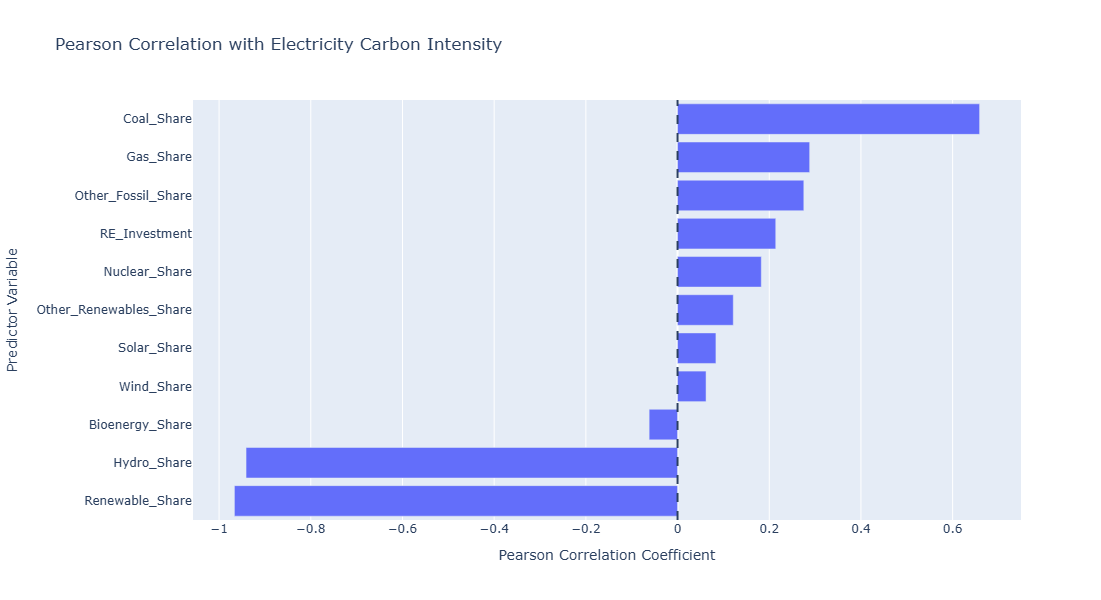

In [151]:
pearson_target_plot = (
    pearson_target
    .reset_index()
)

pearson_target_plot.columns = [
    "Variable",
    "Pearson_Correlation"
]


fig = px.bar(
    pearson_target_plot,
    x="Pearson_Correlation",
    y="Variable",
    orientation="h",
    title="Pearson Correlation with Electricity Carbon Intensity",
    labels={
        "Pearson_Correlation":
            "Pearson Correlation Coefficient",
        "Variable":
            "Predictor Variable"
    }
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.update_layout(
    height=600
)

fig.show()

In [152]:
# SPEARMAN CORRELATION

spearman_corr = (
    RO2_model_data[correlation_columns]
    .corr(method="spearman")
)

spearman_corr.round(3)

,RE_Investment,Solar_Share,Wind_Share,Hydro_Share,Bioenergy_Share,Other_Renewables_Share,Renewable_Share,Coal_Share,Gas_Share,Other_Fossil_Share,Nuclear_Share,Carbon_Intensity
RE_Investment,1.000,0.382,0.434,-0.143,-0.013,0.121,-0.135,0.333,0.150,-0.245,0.316,0.184
Solar_Share,0.382,1.000,0.497,-0.138,0.104,-0.037,-0.074,0.128,0.039,-0.151,0.184,0.107
Wind_Share,0.434,0.497,1.000,-0.394,0.007,0.241,-0.290,0.432,0.098,-0.124,0.376,0.331
Hydro_Share,-0.143,-0.138,-0.394,1.000,-0.190,-0.325,0.934,-0.414,-0.386,-0.493,-0.152,-0.903
Bioenergy_Share,-0.013,0.104,0.007,-0.190,1.000,0.248,-0.065,-0.044,-0.094,0.297,0.219,0.069
Other_Renewables_Share,0.121,-0.037,0.241,-0.325,0.248,1.000,-0.149,0.311,0.008,0.136,0.093,0.207
Renewable_Share,-0.135,-0.074,-0.290,0.934,-0.065,-0.149,1.000,-0.435,-0.475,-0.455,-0.241,-0.952
Coal_Share,0.333,0.128,0.432,-0.414,-0.044,0.311,-0.435,1.000,0.167,-0.123,0.483,0.587
Gas_Share,0.150,0.039,0.098,-0.386,-0.094,0.008,-0.475,0.167,1.000,-0.006,0.162,0.368
Other_Fossil_Share,-0.245,-0.151,-0.124,-0.493,0.297,0.136,-0.455,-0.123,-0.006,1.000,-0.056,0.334


In [153]:
spearman_target = (
    spearman_corr["Carbon_Intensity"]
    .drop("Carbon_Intensity")
    .sort_values()
)

spearman_target.round(3)

Renewable_Share          -0.952
Hydro_Share              -0.903
Bioenergy_Share           0.069
Solar_Share               0.107
RE_Investment             0.184
Other_Renewables_Share    0.207
Nuclear_Share             0.264
Wind_Share                0.331
Other_Fossil_Share        0.334
Gas_Share                 0.368
Coal_Share                0.587
Name: Carbon_Intensity, dtype: float64

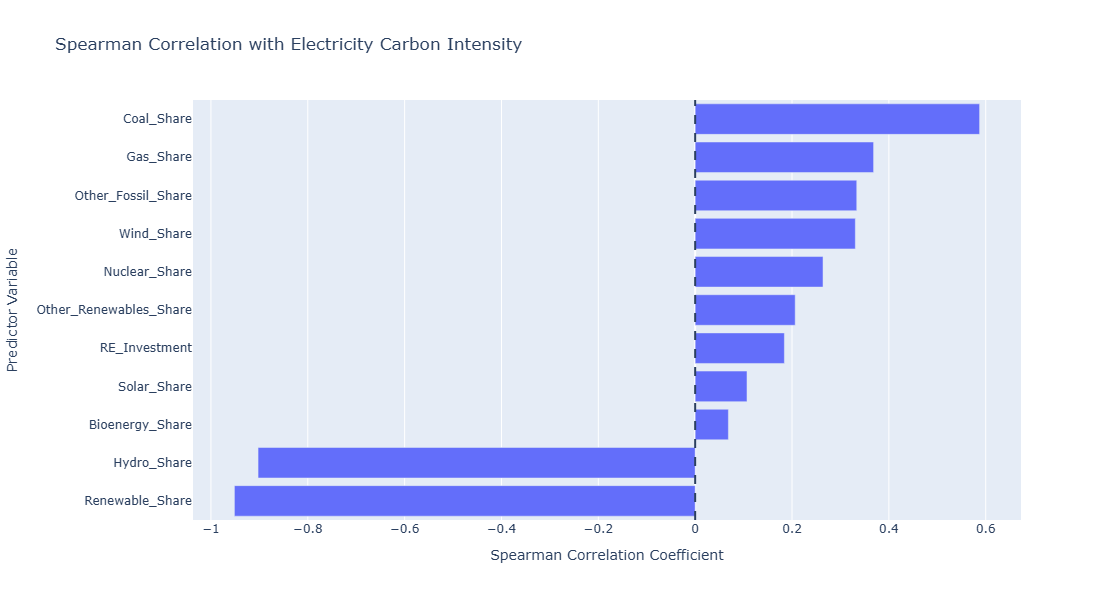

In [154]:
spearman_target_plot = (
    spearman_target
    .reset_index()
)

spearman_target_plot.columns = [
    "Variable",
    "Spearman_Correlation"
]


fig = px.bar(
    spearman_target_plot,
    x="Spearman_Correlation",
    y="Variable",
    orientation="h",
    title="Spearman Correlation with Electricity Carbon Intensity",
    labels={
        "Spearman_Correlation":
            "Spearman Correlation Coefficient",
        "Variable":
            "Predictor Variable"
    }
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.update_layout(
    height=600
)

fig.show()

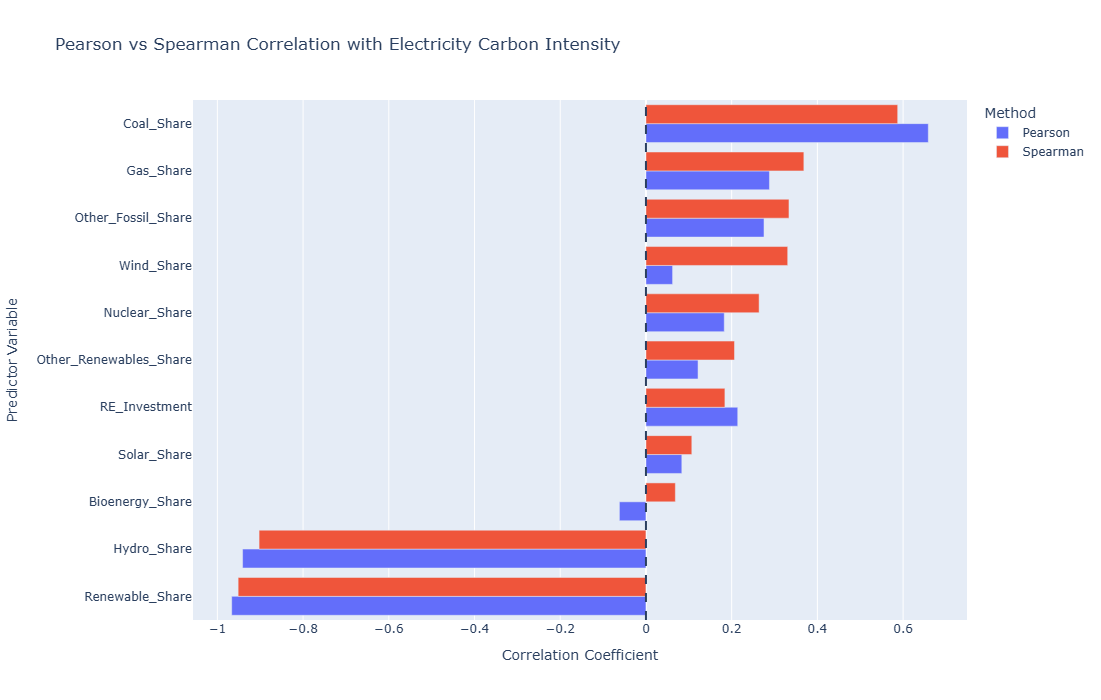

In [155]:
correlation_comparison = pd.DataFrame({
    "Pearson": pearson_target,
    "Spearman": spearman_target
})

correlation_comparison = (
    correlation_comparison
    .sort_values(
        "Spearman"
    )
)

correlation_comparison.round(3)


correlation_comparison_plot = (
    correlation_comparison
    .reset_index()
    .rename(
        columns={
            "index": "Variable"
        }
    )
)


correlation_long = correlation_comparison_plot.melt(
    id_vars="Variable",
    value_vars=[
        "Pearson",
        "Spearman"
    ],
    var_name="Correlation_Method",
    value_name="Correlation"
)


fig = px.bar(
    correlation_long,
    x="Correlation",
    y="Variable",
    color="Correlation_Method",
    barmode="group",
    orientation="h",
    title="Pearson vs Spearman Correlation with Electricity Carbon Intensity",
    labels={
        "Correlation":
            "Correlation Coefficient",
        "Variable":
            "Predictor Variable",
        "Correlation_Method":
            "Method"
    }
)

fig.add_vline(
    x=0,
    line_dash="dash"
)

fig.update_layout(
    height=700
)

fig.show()

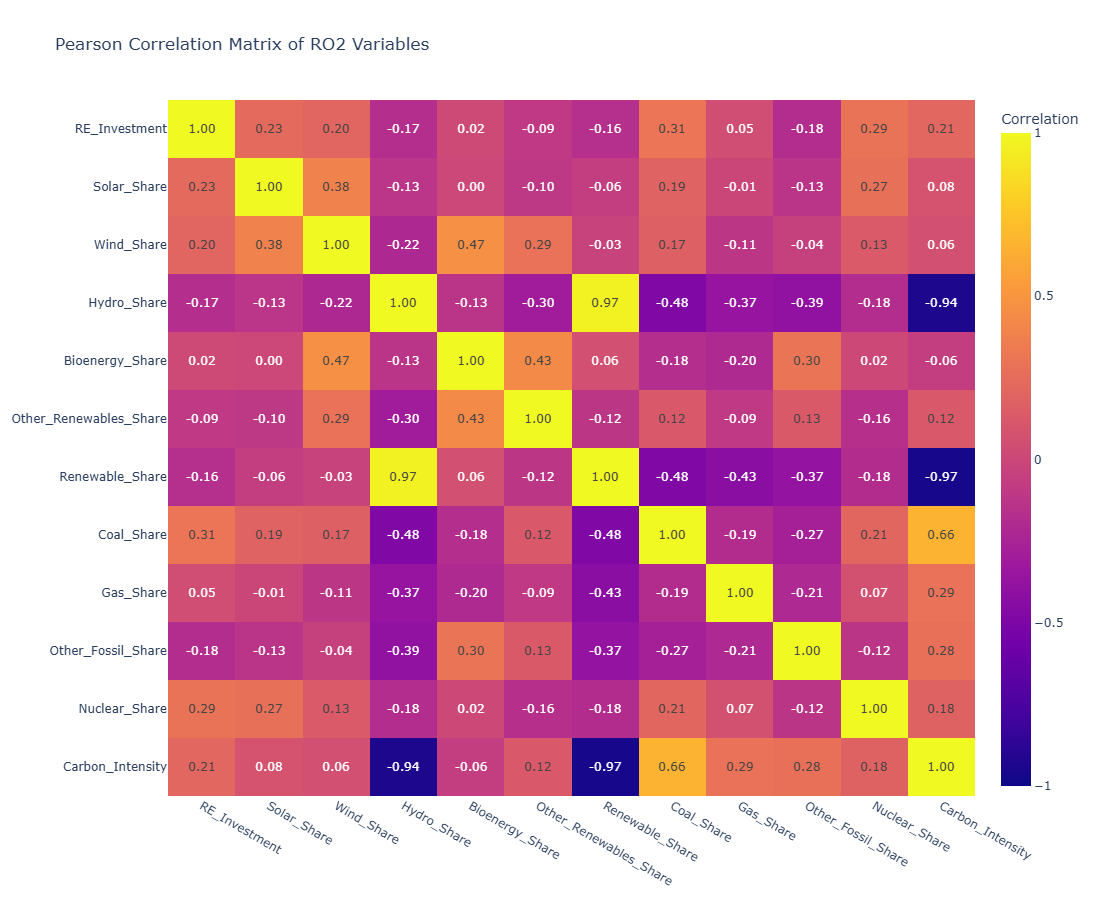

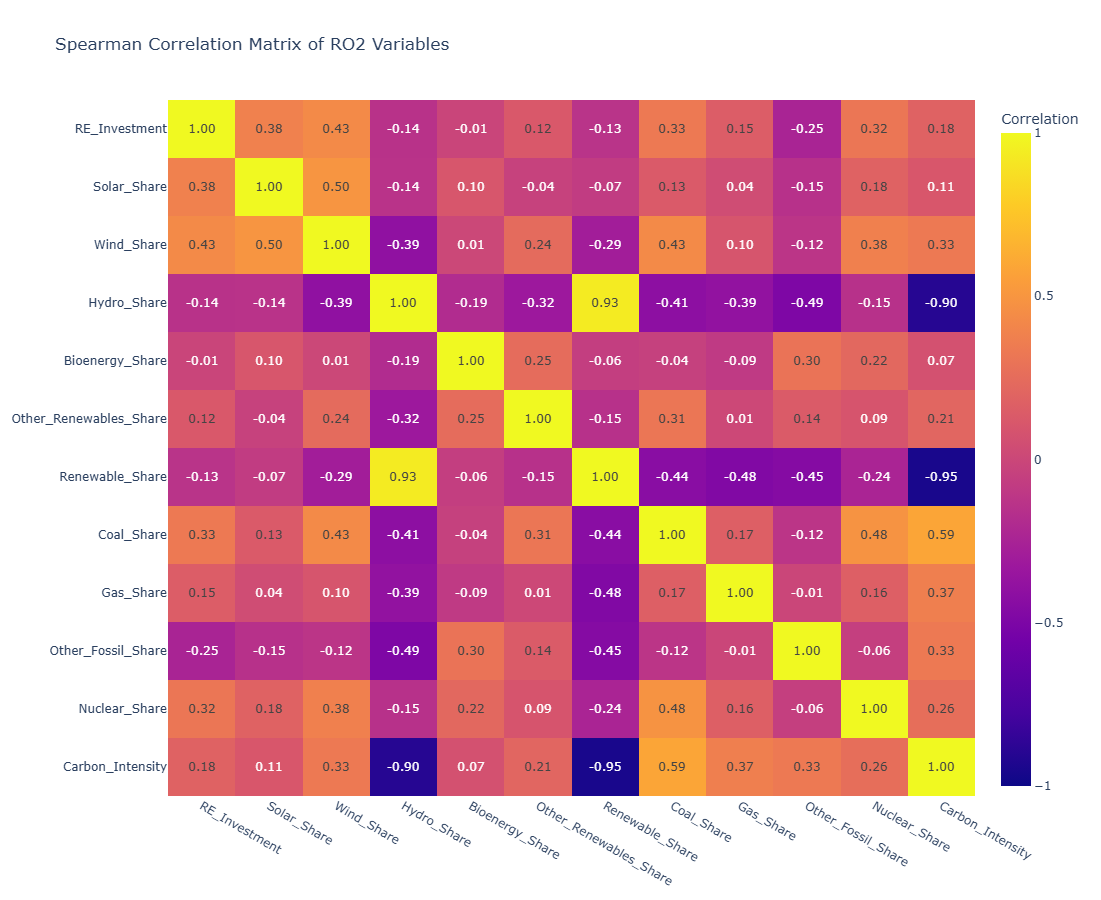

In [157]:
fig = px.imshow(
    pearson_corr,
    text_auto=".2f",
    aspect="auto",
    title="Pearson Correlation Matrix of RO2 Variables",
    labels={
        "color": "Correlation"
    },
    zmin=-1,
    zmax=1
)

fig.update_layout(
    width=1000,
    height=900
)

fig.show()


fig = px.imshow(
    spearman_corr,
    text_auto=".2f",
    aspect="auto",
    title="Spearman Correlation Matrix of RO2 Variables",
    labels={
        "color": "Correlation"
    },
    zmin=-1,
    zmax=1
)

fig.update_layout(
    width=1000,
    height=900
)

fig.show()

In [160]:
RO2_model_data = (
    RO2_model_data
    .sort_values(
        ["Area", "Year"]
    )
    .reset_index(drop=True)
)
RO2_model_data["Investment_Lag1"] = (
    RO2_model_data
    .groupby("Area")["RE_Investment"]
    .shift(1)
)

RO2_model_data["Investment_Lag2"] = (
    RO2_model_data
    .groupby("Area")["RE_Investment"]
    .shift(2)
)

In [161]:
RO2_model_data[
    RO2_model_data["Area"] == "India"
][
    [
        "Area",
        "Year",
        "RE_Investment",
        "Investment_Lag1",
        "Investment_Lag2"
    ]
].head(10)

,Area,Year,RE_Investment,Investment_Lag1,Investment_Lag2
168,India,2000,506.182640,NaN,NaN
169,India,2001,201.363657,506.182640,NaN
170,India,2002,19.195261,201.363657,506.182640
171,India,2003,12.056474,19.195261,201.363657
172,India,2004,290.878020,12.056474,19.195261
173,India,2005,238.539312,290.878020,12.056474
174,India,2006,135.769677,238.539312,290.878020
175,India,2007,494.747409,135.769677,238.539312
176,India,2008,389.236713,494.747409,135.769677
177,India,2009,237.093690,389.236713,494.747409


In [164]:
RO2_model_data[
    [
        "Investment_Lag1",
        "Investment_Lag2"
    ]
].isnull().sum()

Investment_Lag1    22
Investment_Lag2    44
dtype: int64

In [165]:
investment_lag_data = RO2_model_data[
    [
        "RE_Investment",
        "Investment_Lag1",
        "Investment_Lag2",
        "Carbon_Intensity"
    ]
].copy()

In [166]:
investment_lag_pearson = (
    investment_lag_data
    .corr(method="pearson")["Carbon_Intensity"]
    .drop("Carbon_Intensity")
)

investment_lag_pearson.round(3)

investment_lag_spearman = (
    investment_lag_data
    .corr(method="spearman")["Carbon_Intensity"]
    .drop("Carbon_Intensity")
)

investment_lag_spearman.round(3)

RE_Investment      0.184
Investment_Lag1    0.164
Investment_Lag2    0.173
Name: Carbon_Intensity, dtype: float64

In [167]:
RO2_model_data["Log_RE_Investment"] = np.log1p(
    RO2_model_data["RE_Investment"]
)

RO2_model_data["Log_Investment_Lag1"] = np.log1p(
    RO2_model_data["Investment_Lag1"]
)

RO2_model_data["Log_Investment_Lag2"] = np.log1p(
    RO2_model_data["Investment_Lag2"]
)

log_investment_corr = RO2_model_data[
    [
        "Log_RE_Investment",
        "Log_Investment_Lag1",
        "Log_Investment_Lag2",
        "Carbon_Intensity"
    ]
].corr(method="pearson")[
    "Carbon_Intensity"
].drop(
    "Carbon_Intensity"
)

log_investment_corr.round(3)

Log_RE_Investment      0.166
Log_Investment_Lag1    0.145
Log_Investment_Lag2    0.149
Name: Carbon_Intensity, dtype: float64

In [169]:
log_investment_corr.round(3)

Log_RE_Investment      0.166
Log_Investment_Lag1    0.145
Log_Investment_Lag2    0.149
Name: Carbon_Intensity, dtype: float64

In [170]:
feature_set_A = [
    "RE_Investment",
    "Renewable_Share",
    "Coal_Share",
    "Gas_Share",
    "Nuclear_Share"
]

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


X_A = RO2_model_data[
    feature_set_A
].copy()

X_A_const = add_constant(X_A)


vif_A = pd.DataFrame({
    "Variable": X_A_const.columns,
    "VIF": [
        variance_inflation_factor(
            X_A_const.values,
            i
        )
        for i in range(X_A_const.shape[1])
    ]
})


# Remove constant from displayed results
vif_A = vif_A[
    vif_A["Variable"] != "const"
].sort_values(
    "VIF",
    ascending=False
)

vif_A.round(2)

,Variable,VIF
2,Renewable_Share,2.05
3,Coal_Share,1.89
4,Gas_Share,1.65
1,RE_Investment,1.19
5,Nuclear_Share,1.13


In [173]:
feature_set_B = [
    "RE_Investment",

    "Solar_Share",
    "Wind_Share",
    "Hydro_Share",
    "Bioenergy_Share",
    "Other_Renewables_Share",

    "Coal_Share",
    "Gas_Share",
    "Nuclear_Share"
]

X_B = RO2_model_data[
    feature_set_B
].copy()

X_B_const = add_constant(X_B)


vif_B = pd.DataFrame({
    "Variable": X_B_const.columns,
    "VIF": [
        variance_inflation_factor(
            X_B_const.values,
            i
        )
        for i in range(X_B_const.shape[1])
    ]
})


vif_B = vif_B[
    vif_B["Variable"] != "const"
].sort_values(
    "VIF",
    ascending=False
)

vif_B.round(2)

,Variable,VIF
4,Hydro_Share,2.44
7,Coal_Share,2.40
5,Bioenergy_Share,2.04
8,Gas_Share,1.90
3,Wind_Share,1.71
6,Other_Renewables_Share,1.52
2,Solar_Share,1.35
1,RE_Investment,1.26
9,Nuclear_Share,1.23


In [174]:
RO2_model_data[
    [
        "RE_Investment",
        "Investment_Lag1",
        "Investment_Lag2"
    ]
].corr().round(3)

,RE_Investment,Investment_Lag1,Investment_Lag2
RE_Investment,1.000,0.452,0.458
Investment_Lag1,0.452,1.000,0.451
Investment_Lag2,0.458,0.451,1.000


In [175]:
vif_A.round(2)

,Variable,VIF
2,Renewable_Share,2.05
3,Coal_Share,1.89
4,Gas_Share,1.65
1,RE_Investment,1.19
5,Nuclear_Share,1.13


In [176]:
vif_B.round(2)

,Variable,VIF
4,Hydro_Share,2.44
7,Coal_Share,2.40
5,Bioenergy_Share,2.04
8,Gas_Share,1.90
3,Wind_Share,1.71
6,Other_Renewables_Share,1.52
2,Solar_Share,1.35
1,RE_Investment,1.26
9,Nuclear_Share,1.23


In [177]:
RO2_model_data[
    [
        "RE_Investment",
        "Investment_Lag1",
        "Investment_Lag2"
    ]
].corr().round(3)

,RE_Investment,Investment_Lag1,Investment_Lag2
RE_Investment,1.000,0.452,0.458
Investment_Lag1,0.452,1.000,0.451
Investment_Lag2,0.458,0.451,1.000


In [180]:
from sklearn.feature_selection import mutual_info_regression


feature_set_B = [
    "RE_Investment",
    "Solar_Share",
    "Wind_Share",
    "Hydro_Share",
    "Bioenergy_Share",
    "Other_Renewables_Share",
    "Coal_Share",
    "Gas_Share",
    "Nuclear_Share"
]


X_B = RO2_model_data[
    feature_set_B
].copy()

y = RO2_model_data[
    "Carbon_Intensity"
].copy()


mi_B = mutual_info_regression(
    X_B,
    y,
    random_state=42
)



mi_B_results = pd.DataFrame({
    "Variable": feature_set_B,
    "Mutual_Information": mi_B
})

mi_B_results = mi_B_results.sort_values(
    "Mutual_Information",
    ascending=False
)

mi_B_results.round(3)

,Variable,Mutual_Information
3,Hydro_Share,1.805
7,Gas_Share,1.011
6,Coal_Share,0.948
4,Bioenergy_Share,0.570
2,Wind_Share,0.430
8,Nuclear_Share,0.313
1,Solar_Share,0.293
5,Other_Renewables_Share,0.264
0,RE_Investment,0.086


In [181]:
feature_selection_B = pd.DataFrame({
    "Variable": feature_set_B,

    "Pearson": [
        pearson_corr.loc[
            variable,
            "Carbon_Intensity"
        ]
        for variable in feature_set_B
    ],

    "Spearman": [
        spearman_corr.loc[
            variable,
            "Carbon_Intensity"
        ]
        for variable in feature_set_B
    ],

    "Mutual_Information": mi_B
})


feature_selection_B["Abs_Pearson"] = (
    feature_selection_B["Pearson"].abs()
)

feature_selection_B["Abs_Spearman"] = (
    feature_selection_B["Spearman"].abs()
)


feature_selection_B = (
    feature_selection_B
    .sort_values(
        "Mutual_Information",
        ascending=False
    )
)

feature_selection_B.round(3)

,Variable,Pearson,Spearman,Mutual_Information,Abs_Pearson,Abs_Spearman
3,Hydro_Share,-0.941,-0.903,1.805,0.941,0.903
7,Gas_Share,0.288,0.368,1.011,0.288,0.368
6,Coal_Share,0.659,0.587,0.948,0.659,0.587
4,Bioenergy_Share,-0.062,0.069,0.570,0.062,0.069
2,Wind_Share,0.062,0.331,0.430,0.062,0.331
8,Nuclear_Share,0.183,0.264,0.313,0.183,0.264
1,Solar_Share,0.084,0.107,0.293,0.084,0.107
5,Other_Renewables_Share,0.122,0.207,0.264,0.122,0.207
0,RE_Investment,0.214,0.184,0.086,0.214,0.184


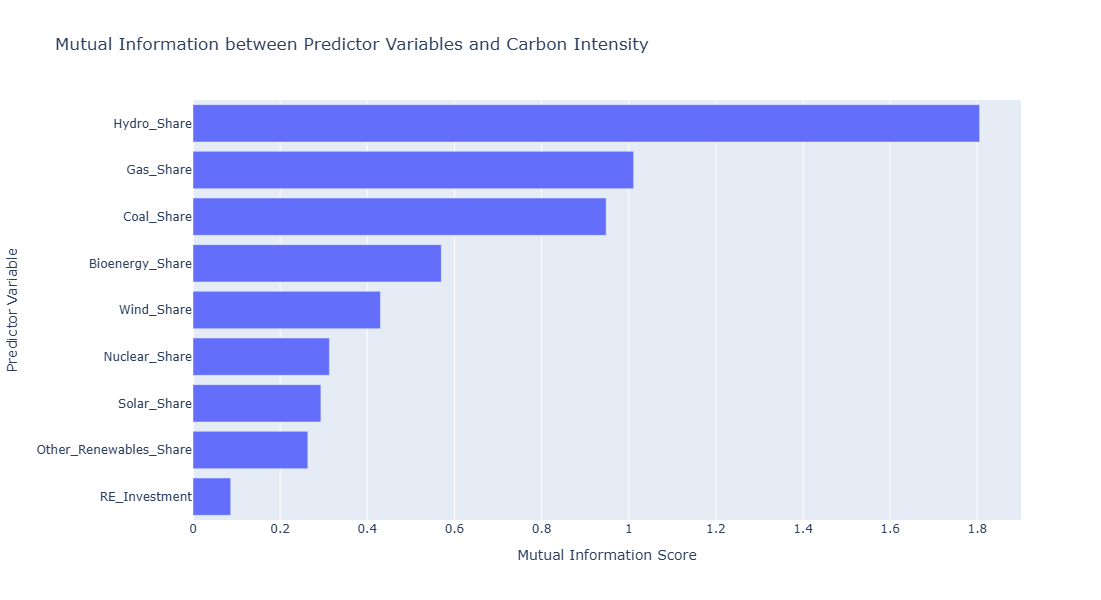

In [182]:
fig = px.bar(
    mi_B_results,
    x="Mutual_Information",
    y="Variable",
    orientation="h",
    title="Mutual Information between Predictor Variables and Carbon Intensity",
    labels={
        "Mutual_Information":
            "Mutual Information Score",
        "Variable":
            "Predictor Variable"
    }
)

fig.update_yaxes(
    categoryorder="total ascending"
)

fig.update_layout(
    height=600
)

fig.show()

In [184]:
feature_set_A = [
    "RE_Investment",
    "Renewable_Share",
    "Coal_Share",
    "Gas_Share",
    "Nuclear_Share"
]


X_A = RO2_model_data[
    feature_set_A
].copy()


mi_A = mutual_info_regression(
    X_A,
    y,
    random_state=42
)


mi_A_results = pd.DataFrame({
    "Variable": feature_set_A,
    "Mutual_Information": mi_A
}).sort_values(
    "Mutual_Information",
    ascending=False
)


mi_A_results.round(3)

,Variable,Mutual_Information
1,Renewable_Share,2.322
3,Gas_Share,1.010
2,Coal_Share,0.941
4,Nuclear_Share,0.312
0,RE_Investment,0.086
